# Оценка эффекта обновления кэшбэк-программы банка: корреляционный анализ и A/B-тест

Учебный командный кейс (5 человек). Данные — транзакционная активность клиентов банка за 2022 год.


Для увеличения лояльности клиентов банка им дается выбор из различных магазинов, где клиент может совершить покупки с кэшбэком. Вам предоставлены данные и транзакционной активности клиентов за 2022г. При это данные поделены
на 2 участка: последние 3 месяца и предшествующие им. Так же кэшбэк делится на 2 типа от банки и от партнеров. Для лучшей осведомленности клиентом им могут рассылаться различные коммуникации о магазинах, где у них есть кэшбэк. В данном
исследовании коммуникации не разбиты по типам, а лишь есть общее число полученных клиентом коммуникаций.

Описание полей:
* cb_merch_last_3_month кэшбэк за последние 3 месяца от партнеров
* cb_bank_last_3_month кэшбэк за последние 3 месяца от банка
* cb_merch_before кэшбэк с 2022-01-01 по 2022-08-01 месяца от партнеров
* cb_bank_before кэшбэк с 2022-01-01 по 2022-08-01 месяца от банка
* cnt_communication число отправленных коммуникаций о кэшбэках
* cnt_activation число активированных предложений за последние 3 месяца
* cnt_view число просмотров предложений с кэшбэком за последние 3 месяца
* Air сумма покупок в категории Авиабилетов за последние 3 месяца
* Beauty shop сумма покупок в категории Красота за последние 3 месяца
* Book store сумма покупок в категории Книги за последние 3 месяца
* Children сумма покупок в категории Дети за последние 3 месяца
* Cinema сумма покупок в категории Кино за последние 3 месяца
* Clothes сумма покупок в категории Одежда за последние 3 месяца
* Electronics сумма покупок в категории Электроника за последние 3 месяца
* Fastfood сумма покупок в категории Фастфуд за последние 3 месяца
* Fuel сумма покупок в категории Топливо за последние 3 месяца
* House — сумма покупок в категории Дом за последние 3 месяца
* Jewelry сумма покупок в категории Украшения за последние 3 месяца
* Other сумма покупок в категории Другое за последние 3 месяца
* Pet shop сумма покупок в категории Животные за последние 3 месяца
* Pharmacies сумма покупок в категории Аптека за последние 3 месяца
* Supermarkets сумма покупок в категории Супермаркеты за последние 3 месяца
* Taxi сумма покупок в категории Такси за последние 3 месяца
* Transport сумма покупок в категории Транспорт за последние 3 месяца
* Air_before сумма покупок в категории Авиабилетовс 2022-01-01 по 2022-08-01
* Beauty shop_before сумма покупок в категории Красота с 2022-01-01 по 2022-08-01
* Book store_before сумма покупок в категории Книги с 2022-01-01 по 2022-08-01
* Children_before сумма покупок в категории Дети с 2022-01-01 по 2022-08-01
* Cinema_before сумма покупок в категории Кино с 2022-01-01 по 2022-08-01
* Clothes_before сумма покупок в категории Одеждас 2022-01-01 по 2022-08-01
* Electronics_before сумма покупок в категории Электроника с 2022-01-01 по 2022-08-01
* Fastfood_before сумма покупок в категории Фастфуд с 2022-01-01 по 2022-08-01
* Fuel_before сумма покупок в категории Топливо с 2022-01-01 по 2022-08-01
* House_before сумма покупок в категории Дом с 2022-01-01 по 2022-08-01
* Jewelry_before сумма покупок в категории Украшения с 2022-01-01 по 2022-08-01
* Other_before сумма покупок в категории Другое с 2022-01-01 по 2022-08-01
* Pet shop_before сумма покупок в категории Животные с 2022-01-01 по 2022-08-01
* Pharmacies_before сумма покупок в категории Аптека с 2022-01-01 по 2022-08-01
* Supermarkets_before сумма покупок в категории Супермаркеты с 2022-01-01 по 2022-08-01
* Taxi_before — сумма покупок в категории Такси с 2022-01-01 по 2022-08-01
* Transport_before сумма покупок в категории Транспорт с 2022-01-01 по 2022-08-01

1. Как взаимосвязаны коммуникации на покупки с кэшбэком?
2. Как взаимосвязаны обороты клиентов и выплаченный кэшбэк?
3. 3 месяца назад произошло глобальное обновление приложения в т.ч. методики взаимодействия с пользователем. Необходимо оценить эффект обновления.
4. Выдвинете собственную гипотезу на основе имеющихся данных.

## Навигация:
* [1. Взаимосвязь коммуникаций с кэшбэком](#1)
* [2. Взаимосвязь оборотов клиентов и выплаченного кешбэка](#2)

In [1]:
# импортируем библиотеки
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import t, norm
from scipy import stats as st
from datetime import datetime 

In [2]:
data = pd.read_csv('../data/cashback.csv', sep=',')
data.head()

,client_id,cb_merch_last_3_month,cb_bank_last_3_month,cb_merch_before,cb_bank_before,cnt_communication,cnt_activation,cnt_view,Air,Beauty shop,Book store,Children,Cinema,Clothes,Electronics,Fastfood,Fuel,House,Jewelry,Other,Pet shop,Pharmacies,Supermarkets,Taxi,Transport,Air_before,Beauty shop_before,Book store_before,Children_before,Cinema_before,Clothes_before,Electronics_before,Fastfood_before,Fuel_before,House_before,Jewelry_before,Other_before,Pet shop_before,Pharmacies_before,Supermarkets_before,Taxi_before,Transport_before
0,162353149,282.0,141.0,119.0,125.0,6,229,606,0.0,109.0,8.0,13.0,0.0,1285.0,0.0,815.0,335.0,23.0,0.0,5265.0,0.0,388.0,4492.0,0.0,99.0,0.0,138.0,202.0,66.0,0.0,1263.0,26.0,498.0,157.0,2621.0,31.0,6232.0,0.0,91.0,5356.0,0.0,119.0
1,666605735,0.0,0.0,0.0,0.0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,12.0,0.0,2.0
2,558610079,0.0,0.0,0.0,0.0,0,51,77,2585.0,0.0,0.0,0.0,0.0,152.0,22.0,265.0,857.0,0.0,0.0,4217.0,0.0,7.0,864.0,0.0,806.0,0.0,0.0,0.0,0.0,0.0,69.0,65.0,527.0,398.0,788.0,0.0,9797.0,0.0,1.0,371.0,0.0,458.0
3,769974329,174.0,0.0,151.0,102.0,3,137,375,0.0,0.0,0.0,0.0,0.0,0.0,0.0,278.0,0.0,217.0,0.0,240.0,0.0,2.0,427.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,107.0,227.0,0.0,0.0,0.0,208.0,0.0,14.0,338.0,0.0,10.0
4,350605405,0.0,0.0,179.0,179.0,4,18,24,0.0,634.0,0.0,0.0,0.0,166.0,0.0,660.0,488.0,89.0,0.0,2794.0,0.0,361.0,2515.0,0.0,0.0,371.0,0.0,7.0,0.0,0.0,14.0,0.0,452.0,372.0,0.0,76.0,486.0,0.0,499.0,2198.0,0.0,14.0


In [3]:
(data['cnt_activation'] <= data['cnt_view']).sum()

np.int64(49442)

In [4]:
(data['cnt_activation'] > data['cnt_view']).sum()

np.int64(558)

In [5]:
data.columns = map(str.lower, data.columns)

In [6]:
data = data.drop(['taxi', 'taxi_before'], axis=1)
data.shape

(50000, 40)

In [7]:
data['total_cost_before'] = data.loc[:, 'air_before':'transport_before'].sum(axis=1)
data['total_cost_after'] = data.loc[:, 'air':'transport'].sum(axis=1)
data.head(1)

,client_id,cb_merch_last_3_month,cb_bank_last_3_month,cb_merch_before,cb_bank_before,cnt_communication,cnt_activation,cnt_view,air,beauty shop,book store,children,cinema,clothes,electronics,fastfood,fuel,house,jewelry,other,pet shop,pharmacies,supermarkets,transport,air_before,beauty shop_before,book store_before,children_before,cinema_before,clothes_before,electronics_before,fastfood_before,fuel_before,house_before,jewelry_before,other_before,pet shop_before,pharmacies_before,supermarkets_before,transport_before,total_cost_before,total_cost_after
0,162353149,282.0,141.0,119.0,125.0,6,229,606,0.0,109.0,8.0,13.0,0.0,1285.0,0.0,815.0,335.0,23.0,0.0,5265.0,0.0,388.0,4492.0,99.0,0.0,138.0,202.0,66.0,0.0,1263.0,26.0,498.0,157.0,2621.0,31.0,6232.0,0.0,91.0,5356.0,119.0,16800.0,12832.0


In [8]:
def ejection(data, columns, threshold):
    for col in columns:
        mean = np.mean(data[col])
        std = np.std(data[col])
        z_score = (data[col] - mean) / std
        ejection_count = data[col][(z_score < -threshold) | (z_score > threshold)].count()
        data = data[(z_score > -threshold) & (z_score < threshold)]
        print(f'В столбце {col} - {ejection_count} выбросов')
    return data

In [9]:
columns = ['cb_merch_last_3_month', 'cb_bank_last_3_month', 'cb_merch_before', 'cb_bank_before', 'total_cost_before', 'total_cost_after']

In [10]:
data = ejection(data, columns, 3)

В столбце cb_merch_last_3_month - 870 выбросов
В столбце cb_bank_last_3_month - 1287 выбросов
В столбце cb_merch_before - 1017 выбросов
В столбце cb_bank_before - 1319 выбросов
В столбце total_cost_before - 568 выбросов
В столбце total_cost_after - 592 выбросов


In [11]:
data.shape

(44347, 42)

## <a class="anchor" id="1"> Взаимосвязь коммуникации с кэшбэком

#### Анализ коммуникаций до обновления

In [12]:
before_cb = data[['cb_merch_before', 'cb_bank_before', 'cnt_communication']].copy() #создаём датафрейм, который содержит столбцы  'cb_merch_before' и 'cb_bank_before', 'cnt_communication'
before_cb['sum_cashback'] = before_cb['cb_merch_before'] + before_cb['cb_bank_before'] #создаём столбец с суммами кешбэка
before_cb.head(3)

,cb_merch_before,cb_bank_before,cnt_communication,sum_cashback
0,119.0,125.0,6,244.0
1,0.0,0.0,0,0.0
2,0.0,0.0,0,0.0


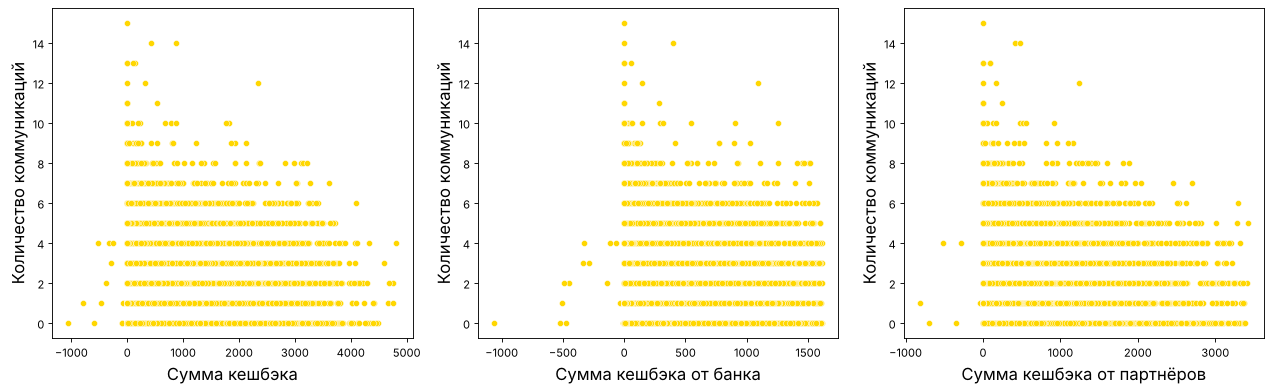

In [13]:
#cписок столбцов
columns = ['sum_cashback', 'cb_bank_before', 'cb_merch_before']
names = ['Сумма кешбэка', 'Сумма кешбэка от банка', 'Сумма кешбэка от партнёров']
#cоздаем подграфики для каждого столбца в одну строку
fig, axes = plt.subplots(nrows=1, ncols=len(columns), figsize=(16, 5))
for ax, col, name in zip(axes, columns, names):
    sns.scatterplot(data=before_cb, x=col, y='cnt_communication', ax=ax, s=30, color='#FFD700') 
    ax.set_xlabel(name, fontsize=15)
    ax.set_ylabel('Количество коммуникаций', fontsize=15)
plt.tight_layout()
plt.show()

Добавим на графики линию регрессии

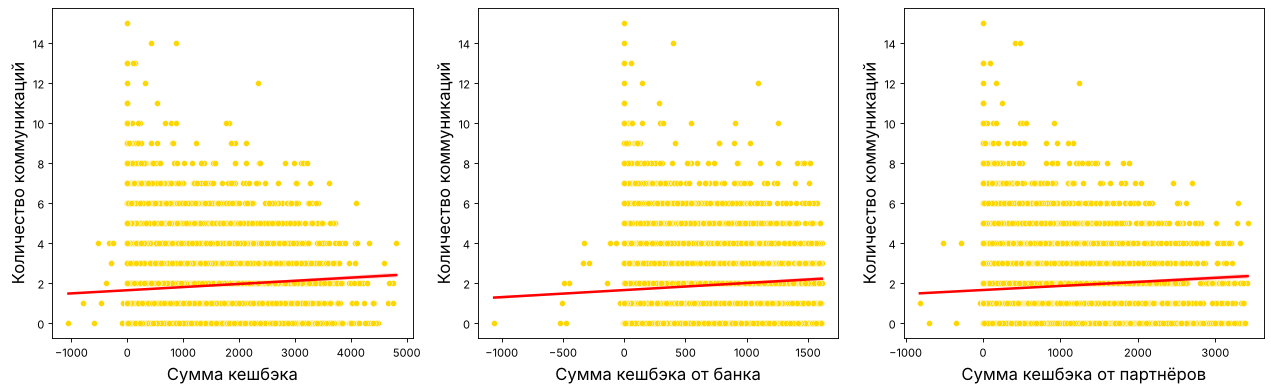

In [14]:
#cоздаем подграфики для каждого столбца в одну строку
fig, axes = plt.subplots(nrows=1, ncols=len(columns), figsize=(16, 5))
for ax, col, name in zip(axes, columns, names):
    sns.scatterplot(data=before_cb, x=col, y='cnt_communication', ax=ax, s=30, color='#FFD700') 
    sns.regplot(data=before_cb, x=col, y='cnt_communication', ax=ax, scatter=False, color='red')
    ax.set_xlabel(name, fontsize=15)
    ax.set_ylabel('Количество коммуникаций', fontsize=15)
plt.tight_layout()
plt.show()

<Axes: >

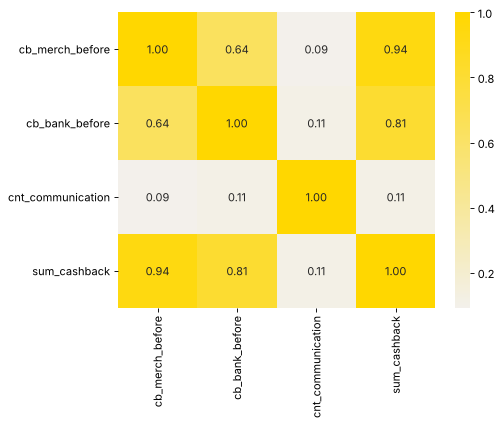

In [15]:
#построим матрицу корреляций
sns.heatmap(before_cb.corr(method='spearman'), annot=True, cmap = sns.light_palette(color='#FFD700', as_cmap=True), fmt=".2f")

Оставим только интересующие нас ячейки для наглядности 

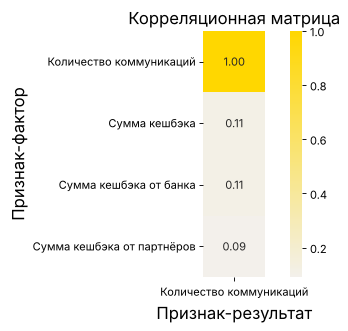

In [16]:
#корреляционная матрица
correlation_matrix = before_cb[['cnt_communication', 'sum_cashback', 'cb_bank_before', 'cb_merch_before']].corr(method='spearman')
#названия переменных
custom_labels = {
    'cnt_communication': 'Количество коммуникаций',
    'sum_cashback': 'Сумма кешбэка',
    'cb_bank_before': 'Сумма кешбэка от банка',
    'cb_merch_before': 'Сумма кешбэка от партнёров',
}
#визуализация
plt.figure(figsize=(8, 4))
sns.heatmap(pd.DataFrame(correlation_matrix.loc['cnt_communication']), annot=True, fmt=".2f", cmap=sns.light_palette(color='#FFD700', as_cmap=True), square=True,
            xticklabels=[custom_labels['cnt_communication']], 
            yticklabels=[custom_labels[col] for col in correlation_matrix.columns])
plt.title('Корреляционная матрица', fontsize=15)
plt.xlabel('Признак-результат', fontsize=15)
plt.ylabel('Признак-фактор', fontsize=15)
plt.show()

Количество коммуникаций имеет слабую связь с кэшбэком, что может указывать на то, что не все коммуникации приводят к получению кэшбэка

In [17]:
from scipy.stats import spearmanr

In [18]:
spearman_corr, spearman_pval = spearmanr(before_cb['cnt_communication'], before_cb['sum_cashback'])
print(f"Коэффициент корреляции Спирмена: {spearman_corr}, p-значение: {spearman_pval}")

Коэффициент корреляции Спирмена: 0.11177825155912056, p-значение: 2.8718296617986634e-123


 Коэффициент корреляции Спирмена равен 0.111, что указывает на слабую положительную корреляцию между количеством коммуникаций и суммой кешбэка

#### Анализ категоризации пользователей по количеству коммуникаций

In [19]:
#осуществляем категоризацию
before_cb['communication_segment'] = pd.cut(before_cb['cnt_communication'], bins=4, labels=['малое количество', 'среднее количество', 'количество выше среднего', 'большое количество'])
before_cb.head(1)

,cb_merch_before,cb_bank_before,cnt_communication,sum_cashback,communication_segment
0,119.0,125.0,6,244.0,среднее количество


In [20]:
before_cb['cnt_communication'].value_counts(bins=4)

(-0.016, 3.75]    37171
(3.75, 7.5]        7000
(7.5, 11.25]        166
(11.25, 15.0]        10
Name: count, dtype: int64

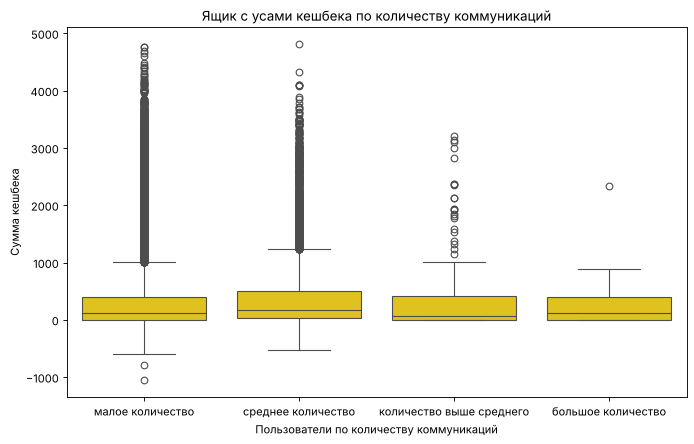

In [21]:
plt.figure(figsize=(10, 6))
sns.boxplot(y='sum_cashback', x='communication_segment', data=before_cb, color='#FFD700')
plt.xlabel('Пользователи по количеству коммуникаций')
plt.ylabel('Сумма кешбека')
plt.title('Ящик с усами кешбека по количеству коммуникаций')
plt.show()

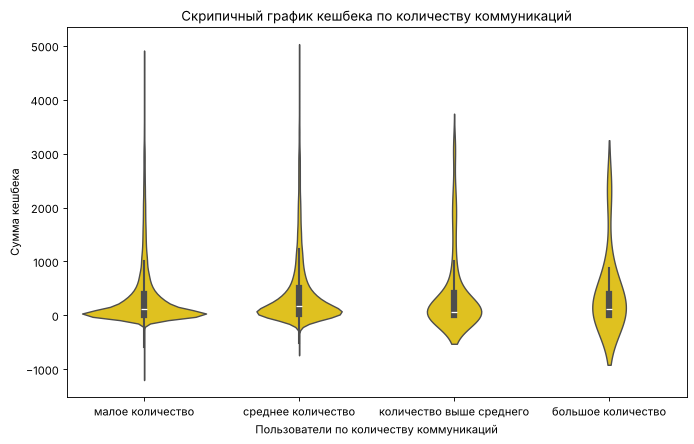

In [22]:
plt.figure(figsize=(10, 6))
sns.violinplot(y='sum_cashback', x='communication_segment', data=before_cb, color='#FFD700')
plt.xlabel('Пользователи по количеству коммуникаций')
plt.ylabel('Сумма кешбека')
plt.title('Скрипичный график кешбека по количеству коммуникаций')
plt.show()

 Из анализа боксплотов и скрипичных графиков видно, что медиана суммы кешбека имеет наибольшее значение при среднем количестве коммуникаций. По скрипкам видно, что с переходом в следующую группу данные распределяются равномернее. А количество  выбросов уменьшается, это объясняется тем, что количество наблюдений уменьшается с переходом в другую группы. Отрицательные выбросы наблюдаются только у группы пользователей с малым количеством коммуникаций.

#### Анализ категоризации пользователей по сумме выплат

In [23]:
#осуществляем категоризацию
before_cb['sum_cashback_interval_cut'] = pd.cut(before_cb['sum_cashback'], bins=4, labels=['малые выплаты', 'средние выплаты', 'выплаты выше среднего', 'высокие выплаты'])
before_cb.head(1)

,cb_merch_before,cb_bank_before,cnt_communication,sum_cashback,communication_segment,sum_cashback_interval_cut
0,119.0,125.0,6,244.0,среднее количество,малые выплаты


In [24]:
before_cb['sum_cashback'].value_counts(bins=4)

(-1057.865, 414.0]    33144
(414.0, 1880.0]        9166
(1880.0, 3346.0]       1855
(3346.0, 4812.0]        182
Name: count, dtype: int64

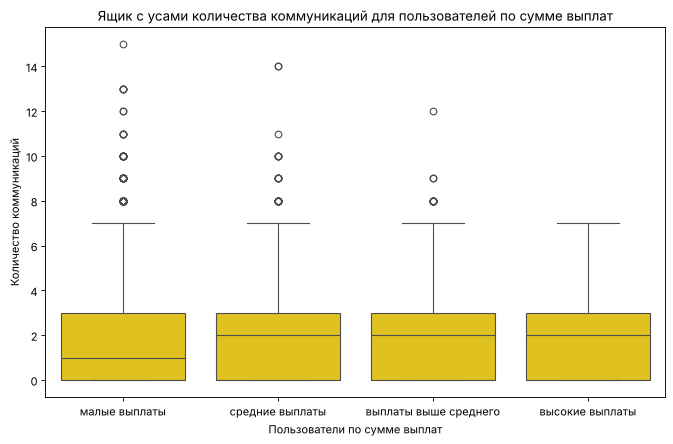

In [25]:
plt.figure(figsize=(10, 6))
sns.boxplot(y='cnt_communication', x='sum_cashback_interval_cut', data=before_cb, color='#FFD700')
plt.xlabel('Пользователи по сумме выплат')
plt.ylabel('Количество коммуникаций')
plt.title('Ящик с усами количества коммуникаций для пользователей по сумме выплат')
plt.show()

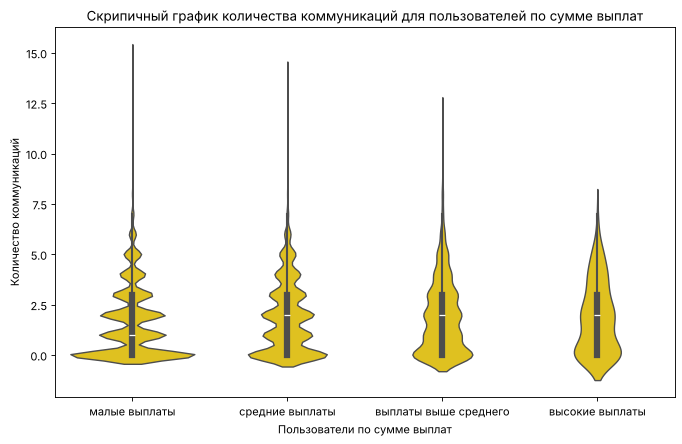

In [26]:
plt.figure(figsize=(10, 6))
sns.violinplot(y='cnt_communication', x='sum_cashback_interval_cut', data=before_cb, color='#FFD700')
plt.xlabel('Пользователи по сумме выплат')
plt.ylabel('Количество коммуникаций')
plt.title('Скрипичный график количества коммуникаций для пользователей по сумме выплат')
plt.show()

 Из анализа боксплотов и скрипичных графиков видно, что медиана количества коммуникаций растет с объемом выплат. По скрипкам видно, что с переходом в следующую группу данные распределяются равномернее. А количество  выбросов уменьшается, это объясняется тем, что количество наблюдений уменьшается с переходом в другую группы.

#### Анализ коммуникаций после обновления

In [27]:
last_3_month_cb = data[['cb_merch_last_3_month','cb_bank_last_3_month', 'cnt_activation', 'cnt_view']].copy()
last_3_month_cb['cnt_after'] = last_3_month_cb['cnt_activation'] + last_3_month_cb['cnt_view']
last_3_month_cb['sum_cashback'] = last_3_month_cb['cb_merch_last_3_month'] + last_3_month_cb['cb_bank_last_3_month']
last_3_month_cb.head(3)

,cb_merch_last_3_month,cb_bank_last_3_month,cnt_activation,cnt_view,cnt_after,sum_cashback
0,282.0,141.0,229,606,835,423.0
1,0.0,0.0,0,0,0,0.0
2,0.0,0.0,51,77,128,0.0


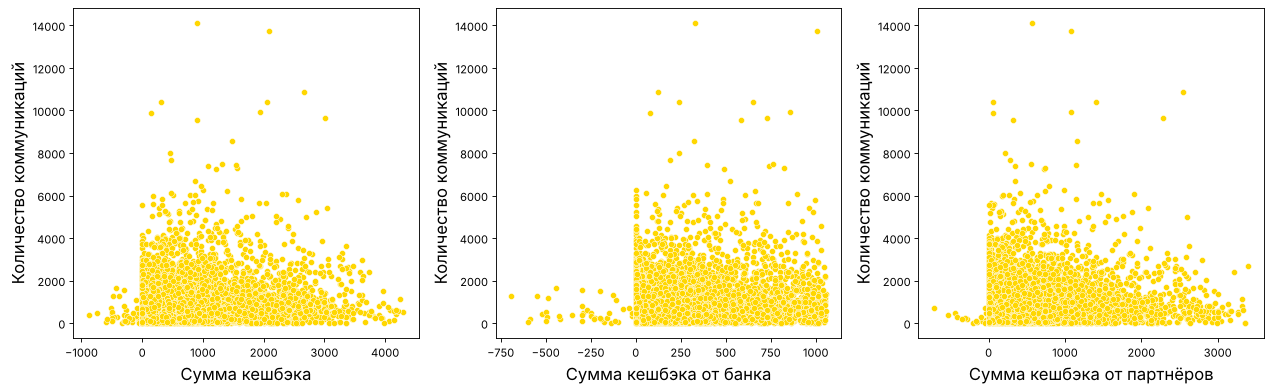

In [28]:
#cписок столбцов
columns = ['sum_cashback', 'cb_bank_last_3_month', 'cb_merch_last_3_month']
names = ['Сумма кешбэка', 'Сумма кешбэка от банка', 'Сумма кешбэка от партнёров']
#cоздаем подграфики для каждого столбца в одну строку
fig, axes = plt.subplots(nrows=1, ncols=len(columns), figsize=(16, 5))
for ax, col, name in zip(axes, columns, names):
    sns.scatterplot(data = last_3_month_cb, x=col, y='cnt_after', ax=ax, s=30, color='#FFD700')
    ax.set_xlabel(name, fontsize=15)
    ax.set_ylabel('Количество коммуникаций', fontsize=15)
plt.tight_layout()
plt.show()

Добавим на графики линию регрессии

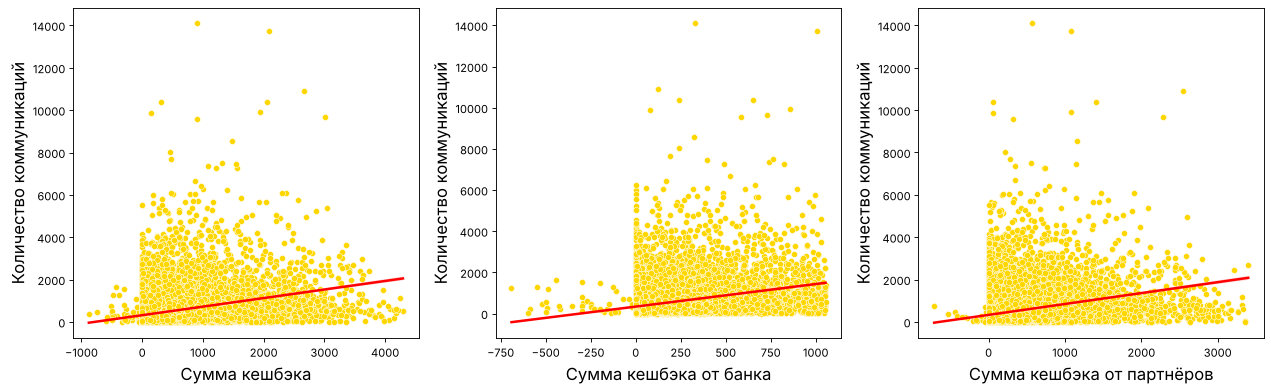

In [29]:
#cоздаем подграфики для каждого столбца в одну строку
fig, axes = plt.subplots(nrows=1, ncols=len(columns), figsize=(16, 5))
for ax, col, name in zip(axes, columns, names):
    sns.scatterplot(data = last_3_month_cb, x=col, y='cnt_after', ax=ax, s=30, color='#FFD700')  
    sns.regplot(data=last_3_month_cb, x=col, y='cnt_after', ax=ax, scatter=False, color='red')
    ax.set_xlabel(name, fontsize=15)
    ax.set_ylabel('Количество коммуникаций', fontsize=15)
plt.tight_layout()
plt.show()

<Axes: >

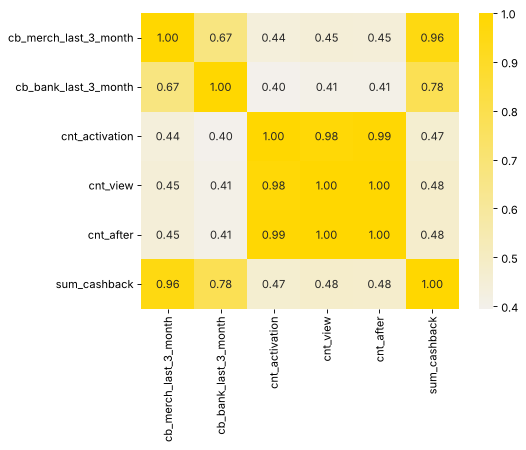

In [30]:
sns.heatmap(last_3_month_cb.corr(method='spearman'), annot=True, cmap=sns.light_palette(color='#FFD700', as_cmap=True), fmt=".2f")

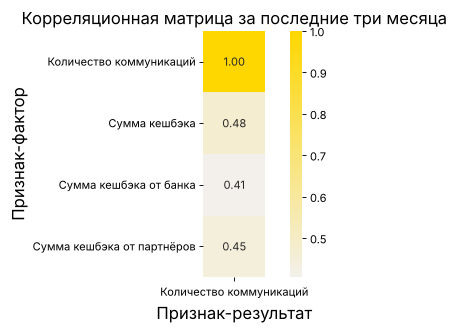

In [31]:
#корреляционная матрица
correlation_matrix = last_3_month_cb[['cnt_after', 'sum_cashback', 'cb_bank_last_3_month', 'cb_merch_last_3_month']].corr(method='spearman')
#названия переменных
custom_labels = {
    'cnt_after': 'Количество коммуникаций',
    'sum_cashback': 'Сумма кешбэка',
    'cb_bank_last_3_month': 'Сумма кешбэка от банка',
    'cb_merch_last_3_month': 'Сумма кешбэка от партнёров',
}
#визуализация
plt.figure(figsize=(8, 4))
sns.heatmap(pd.DataFrame(correlation_matrix.loc['cnt_after']), annot=True, fmt=".2f", cmap=sns.light_palette(color='#FFD700', as_cmap=True), square=True,
            xticklabels=[custom_labels['cnt_after']], 
            yticklabels=[custom_labels[col] for col in correlation_matrix.columns])
plt.title('Корреляционная матрица за последние три месяца', fontsize=15)
plt.xlabel('Признак-результат', fontsize=15)
plt.ylabel('Признак-фактор', fontsize=15)
plt.show()

Количество коммуникаций имеет слабую связь с кэшбэком, что может указывать на то, что не все коммуникации приводят к получению кэшбэка. Однако важно заметить, что связь стала сильнее за последние 3 месяца.

In [32]:
spearman_corr, spearman_pval = spearmanr(last_3_month_cb['cnt_after'], last_3_month_cb['sum_cashback'])
print(f"Коэффициент корреляции Спирмена: {spearman_corr}, p-значение: {spearman_pval}")

Коэффициент корреляции Спирмена: 0.47703886101688836, p-значение: 0.0


За последние 3 месяца связь между количеством коммуникаций и суммой кешбэка также слабая положительная, но намного сильнее, чем в предыдущий период

 Коэффициент корреляции Спирмена равен 0.477, что указывает на умеренную положительную корреляцию между количеством коммуникаций и суммой кешбэка после обновления. Но после обновления связь стала более тесной, чем до обновления 

#### Анализ категоризации пользователей по количеству коммуникаций после обновления

In [33]:
#осуществляем категоризацию
last_3_month_cb['communication_segment_after'] = pd.cut(last_3_month_cb['cnt_after'], bins=4, labels=['малое количество', 'среднее количество', 'количество выше среднего', 'большое количество'])
last_3_month_cb.head(1)

,cb_merch_last_3_month,cb_bank_last_3_month,cnt_activation,cnt_view,cnt_after,sum_cashback,communication_segment_after
0,282.0,141.0,229,606,835,423.0,малое количество


In [34]:
last_3_month_cb['cnt_after'].value_counts(bins=4)

(-14.113999999999999, 3528.25]    44170
(3528.25, 7056.5]                   160
(7056.5, 10584.75]                   14
(10584.75, 14113.0]                   3
Name: count, dtype: int64

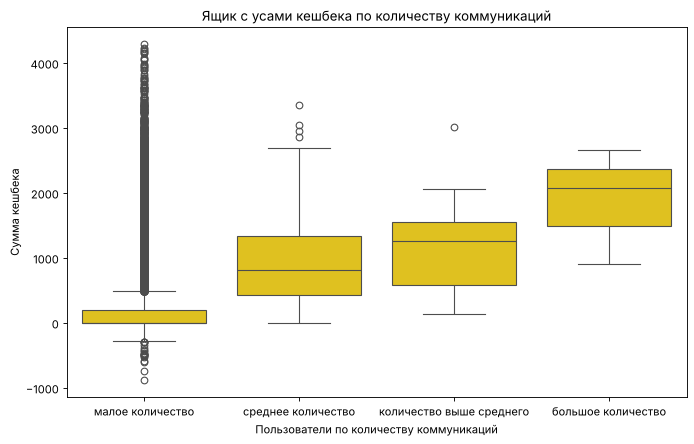

In [35]:
plt.figure(figsize=(10, 6))
sns.boxplot(y='sum_cashback', x='communication_segment_after', data=last_3_month_cb, color='#FFD700')
plt.xlabel('Пользователи по количеству коммуникаций')
plt.ylabel('Сумма кешбека')
plt.title('Ящик с усами кешбека по количеству коммуникаций')
plt.show()

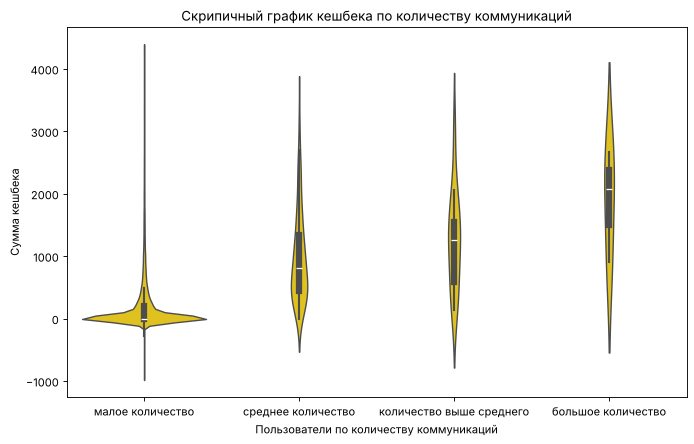

In [36]:
plt.figure(figsize=(10, 6))
sns.violinplot(y='sum_cashback', x='communication_segment_after', data=last_3_month_cb, color='#FFD700')
plt.xlabel('Пользователи по количеству коммуникаций')
plt.ylabel('Сумма кешбека')
plt.title('Скрипичный график кешбека по количеству коммуникаций')
plt.show()

 Из анализа боксплотов и скрипичных графиков видно, что медиана суммы кешбека растет с количеством коммуникаций. По скрипкам видно, что с переходом в следующую группу данные распределяются равномернее. А количество  выбросов уменьшается, это объясняется тем, что количество наблюдений уменьшается с переходом в другую группы. Отрицательные выбросы наблюдаются только у группы пользователей с малым количеством коммуникаций. 

#### Анализ категоризации пользователей по сумме выплат после обновления

In [37]:
#осуществляем категоризацию
last_3_month_cb['sum_cashback_interval_cut'] = pd.cut(last_3_month_cb['sum_cashback'], bins=4, labels=['малые выплаты', 'средние выплаты', 'выплаты выше среднего', 'высокие выплаты'])
last_3_month_cb.head(1)

,cb_merch_last_3_month,cb_bank_last_3_month,cnt_activation,cnt_view,cnt_after,sum_cashback,communication_segment_after,sum_cashback_interval_cut
0,282.0,141.0,229,606,835,423.0,малое количество,средние выплаты


In [38]:
last_3_month_cb['sum_cashback'].value_counts(bins=4)

(-884.173, 414.0]    37833
(414.0, 1707.0]       5460
(1707.0, 3000.0]       942
(3000.0, 4293.0]       112
Name: count, dtype: int64

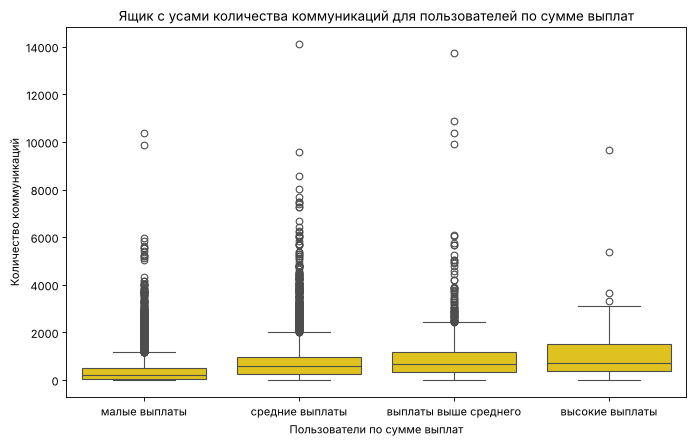

In [39]:
plt.figure(figsize=(10, 6))
sns.boxplot(y='cnt_after', x='sum_cashback_interval_cut', data=last_3_month_cb, color='#FFD700')
plt.xlabel('Пользователи по сумме выплат')
plt.ylabel('Количество коммуникаций')
plt.title('Ящик с усами количества коммуникаций для пользователей по сумме выплат')
plt.show()

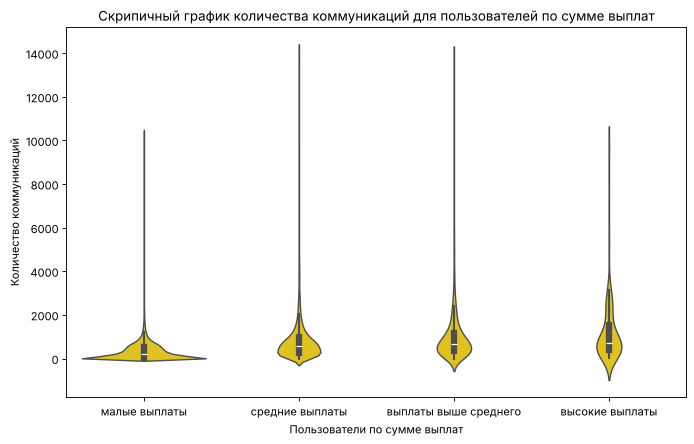

In [40]:
plt.figure(figsize=(10, 6))
sns.violinplot(y='cnt_after', x='sum_cashback_interval_cut', data=last_3_month_cb, color='#FFD700')
plt.xlabel('Пользователи по сумме выплат')
plt.ylabel('Количество коммуникаций')
plt.title('Скрипичный график количества коммуникаций для пользователей по сумме выплат')
plt.show()

 Из анализа боксплотов и скрипичных графиков видно, что медиана количества коммуникаций незначительно растет с объемом выплат. Также незначительно растет межквартильный размах, что говорит об увеличении устойчивости данных. По скрипкам видно, что с переходом в следующую группу данные распределяются равномернее. А количество  выбросов уменьшается, это объясняется, тем что количество наблюдений уменьшается с переходом в другую группы. Видно, что после обновления стало значительно больше количество коммуникаций с пользователями

## <a class="anchor" id="2"> Взаимосвязь оборотов клиентов и выплаченного кешбэка

#### Анализ взаимосвязей до обновления

In [41]:
before = data.loc[:, 'cb_merch_before':'cb_bank_before'] #создаём датафрейм, который содержит столбцы  'cb_merch_before' и 'cb_bank_before'.
before['sum_before'] = data.loc[:, 'air_before':'transport_before'].sum(axis=1) #создаём столбец с суммами покупок
before['sum_cashback'] = before['cb_merch_before'] + before['cb_bank_before'] #создаём столбец с суммами кешбэка
before['mean_sum'] = data.loc[:, 'air_before':'transport_before'].mean(axis=1) #создаём столбец со средними значениями с суммой покупок

In [42]:
before.head(1)

,cb_merch_before,cb_bank_before,sum_before,sum_cashback,mean_sum
0,119.0,125.0,16800.0,244.0,1050.0


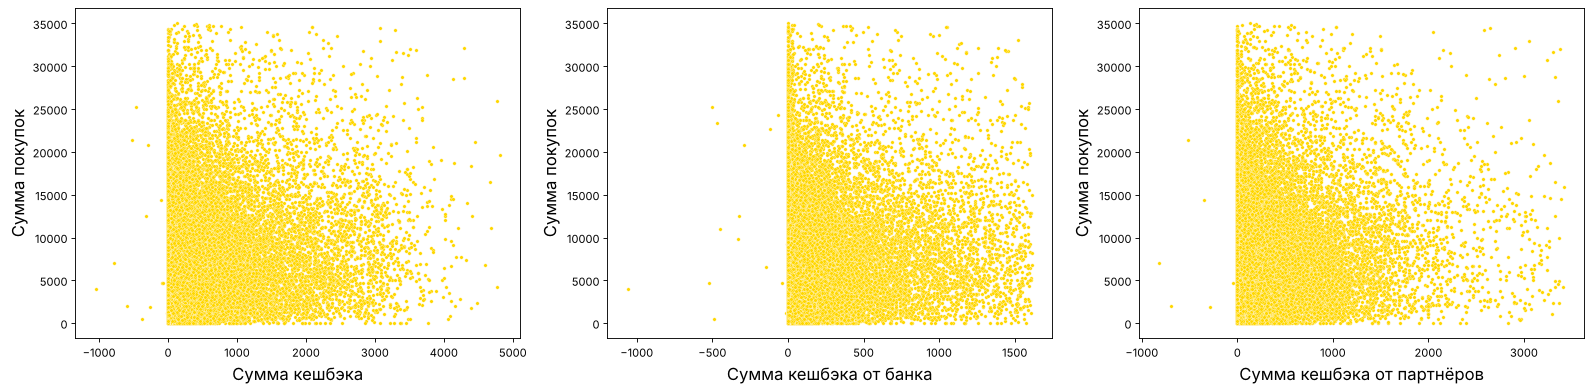

In [43]:
#cписок столбцов
columns = ['sum_cashback', 'cb_bank_before', 'cb_merch_before']
names = ['Сумма кешбэка', 'Сумма кешбэка от банка', 'Сумма кешбэка от партнёров']
#cоздаем подграфики для каждого столбца в одну строку
fig, axes = plt.subplots(nrows=1, ncols=len(columns), figsize=(20, 5))
for ax, col, name in zip(axes, columns, names):
    sns.scatterplot(data=before, x=col, y='sum_before', ax=ax, s=10, color='#FFD700') 
    ax.set_xlabel(name, fontsize=15)
    ax.set_ylabel('Сумма покупок', fontsize=15)
plt.tight_layout()
plt.show()

Добавим на графики линию регрессии

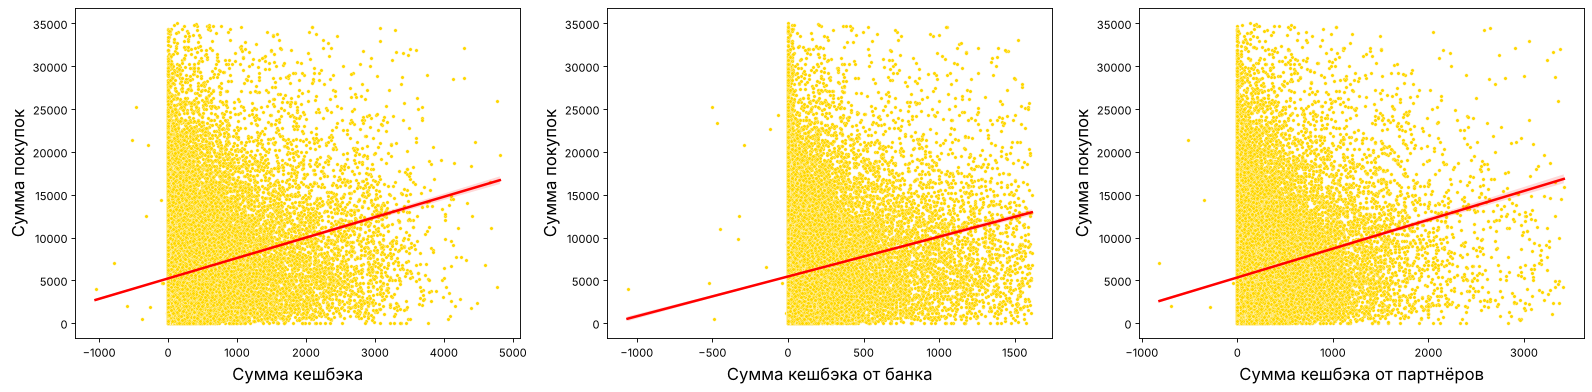

In [44]:
#cоздаем подграфики для каждого столбца в одну строку
fig, axes = plt.subplots(nrows=1, ncols=len(columns), figsize=(20, 5))
for ax, col, name in zip(axes, columns, names):
    sns.scatterplot(data=before, x=col, y='sum_before', ax=ax, s=10, color='#FFD700') 
    sns.regplot(data=before, x=col, y='sum_before', ax=ax, scatter=False, color='red')
    ax.set_xlabel(name, fontsize=15)
    ax.set_ylabel('Сумма покупок', fontsize=15)
plt.tight_layout()
plt.show()

<Axes: >

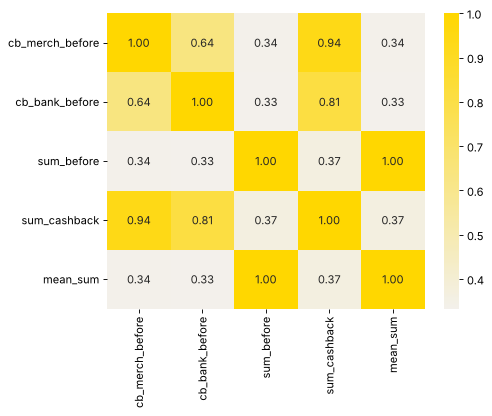

In [45]:
#построим матрицу корреляций
sns.heatmap(before.corr(method='spearman'), annot=True, cmap = sns.light_palette(color='#FFD700', as_cmap=True), fmt=".2f")

Оставим только интересующие нас ячейки для наглядности 

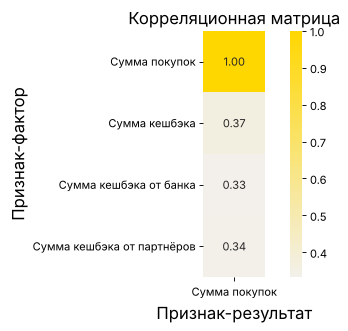

In [46]:
#корреляционная матрица
correlation_matrix = before[['sum_before', 'sum_cashback', 'cb_bank_before', 'cb_merch_before']].corr(method='spearman')
#названия переменных
custom_labels = {
    'sum_before': 'Сумма покупок',
    'sum_cashback': 'Сумма кешбэка',
    'cb_bank_before': 'Сумма кешбэка от банка',
    'cb_merch_before': 'Сумма кешбэка от партнёров',
}
#визуализация
plt.figure(figsize=(8, 4))
sns.heatmap(pd.DataFrame(correlation_matrix.loc['sum_before']), annot=True, fmt=".2f", cmap=sns.light_palette(color='#FFD700', as_cmap=True), square=True,
            xticklabels=[custom_labels['sum_before']], 
            yticklabels=[custom_labels[col] for col in correlation_matrix.columns])
plt.title('Корреляционная матрица', fontsize=15)
plt.xlabel('Признак-результат', fontsize=15)
plt.ylabel('Признак-фактор', fontsize=15)
plt.show()

Сумма расходов имеет слабую связь с кэшбэком, что может указывать на то, что не все расходы приводят к получению кэшбэка

In [47]:
from scipy.stats import spearmanr

In [48]:
spearman_corr, spearman_pval = spearmanr(before['sum_before'], before['sum_cashback'])
print(f"Коэффициент корреляции Спирмена: {spearman_corr}, p-значение: {spearman_pval}")

Коэффициент корреляции Спирмена: 0.36578858315479346, p-значение: 0.0


 Коэффициент корреляции Спирмена равен 0.366, что указывает на умеренную положительную корреляцию между суммой покупок и суммой кешбэка до обновления

#### Анализ категоризации пользователей по сумме покупок

In [49]:
#осуществляем категоризацию
before['sum_before_interval_cut'] = pd.cut(before['sum_before'], bins=4, labels=['малые траты', 'средние траты', 'траты выше среднего', 'высокие траты'])
before.head(1)

,cb_merch_before,cb_bank_before,sum_before,sum_cashback,mean_sum,sum_before_interval_cut
0,119.0,125.0,16800.0,244.0,1050.0,средние траты


In [50]:
before['sum_before'].value_counts(bins=4)

(-35.058, 8764.25]     33689
(8764.25, 17528.5]      8356
(17528.5, 26292.75]     1849
(26292.75, 35057.0]      453
Name: count, dtype: int64

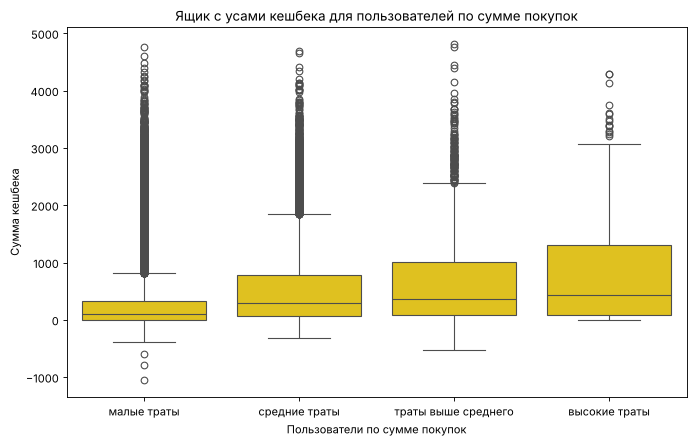

In [51]:
plt.figure(figsize=(10, 6))
sns.boxplot(y='sum_cashback', x='sum_before_interval_cut', data=before, color='#FFD700')
plt.xlabel('Пользователи по сумме покупок')
plt.ylabel('Сумма кешбека')
plt.title('Ящик с усами кешбека для пользователей по сумме покупок')
plt.show()

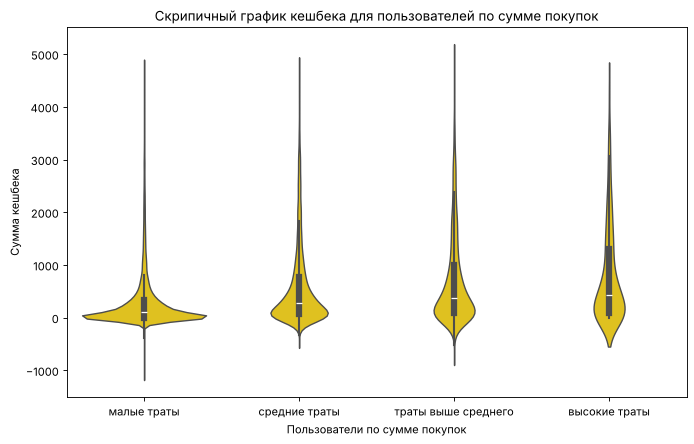

In [52]:
plt.figure(figsize=(10, 6))
sns.violinplot(y='sum_cashback', x='sum_before_interval_cut', data=before, color='#FFD700')
plt.xlabel('Пользователи по сумме покупок')
plt.ylabel('Сумма кешбека')
plt.title('Скрипичный график кешбека для пользователей по сумме покупок')
plt.show()

 Из анализа боксплотов и скрипичных графиков видно, что медиана суммы кешбека растет с объемом покупок. Также растет межквартильный размах, что говорит об увеличении устойчивости данных. По скрипкам видно, что с переходом в следующую группу данные распределяются равномернее. А количество  выбросов уменьшается, это объясняется тем, что количество наблюдений уменьшается с переходом в другую группы. Отрицательные выбросы наблюдаются только у группы пользователей с малыми тратами

#### Анализ категоризации пользователей по сумме выплат

In [53]:
#осуществляем категоризацию
before['sum_cashback_interval_cut'] = pd.cut(before['sum_cashback'], bins=4, labels=['малые выплаты', 'средние выплаты', 'выплаты выше среднего', 'высокие выплаты'])
before.head(1)

,cb_merch_before,cb_bank_before,sum_before,sum_cashback,mean_sum,sum_before_interval_cut,sum_cashback_interval_cut
0,119.0,125.0,16800.0,244.0,1050.0,средние траты,малые выплаты


In [54]:
before['sum_cashback'].value_counts(bins=4)

(-1057.865, 414.0]    33144
(414.0, 1880.0]        9166
(1880.0, 3346.0]       1855
(3346.0, 4812.0]        182
Name: count, dtype: int64

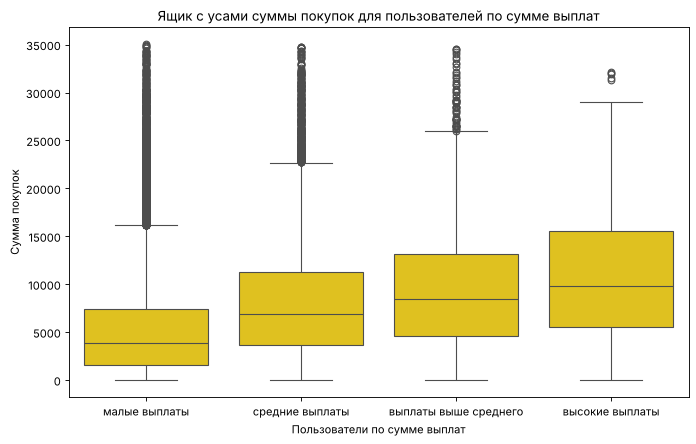

In [55]:
plt.figure(figsize=(10, 6))
sns.boxplot(y='sum_before', x='sum_cashback_interval_cut', data=before, color='#FFD700')
plt.xlabel('Пользователи по сумме выплат')
plt.ylabel('Сумма покупок')
plt.title('Ящик с усами суммы покупок для пользователей по сумме выплат')
plt.show()

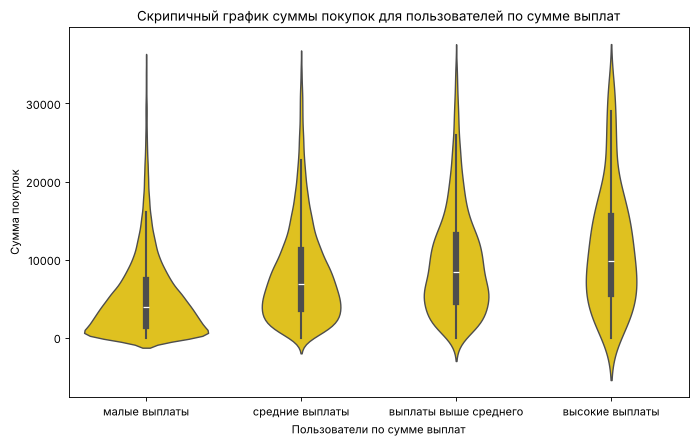

In [56]:
plt.figure(figsize=(10, 6))
sns.violinplot(y='sum_before', x='sum_cashback_interval_cut', data=before, color='#FFD700')
plt.xlabel('Пользователи по сумме выплат')
plt.ylabel('Сумма покупок')
plt.title('Скрипичный график суммы покупок для пользователей по сумме выплат')
plt.show()

 Из анализа боксплотов и скрипичных графиков видно, что медиана суммы покупок растет с объемом выплат. Также растет межквартильный размах, что говорит об увеличении устойчивости данных. По скрипкам видно, что с переходом в следующую группу данные распределяются равномернее. А количество  выбросов уменьшается, это объясняется тем, что количество наблюдений уменьшается с переходом в другую группы

#### Анализ взаимосвязей после обновления

In [57]:
last_3_month = data.loc[:, 'cb_merch_last_3_month':'cb_bank_last_3_month']
last_3_month['sum_after'] = data.loc[:, 'air':'transport'].sum(axis=1)
last_3_month['sum_cashback'] = last_3_month['cb_merch_last_3_month'] + last_3_month['cb_bank_last_3_month']
last_3_month['mean_sum'] = data.loc[:, 'air':'transport'].mean(axis=1)

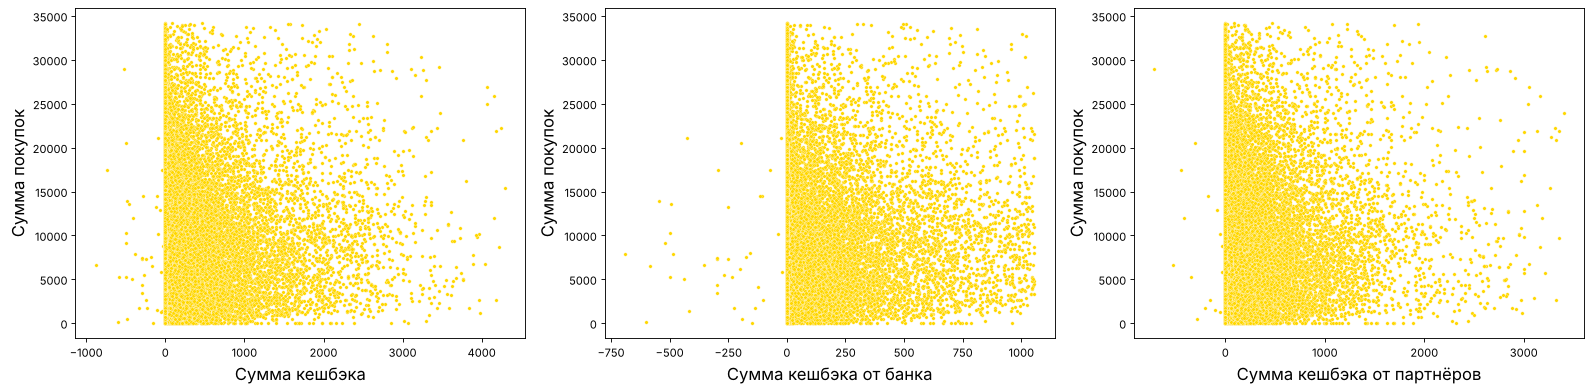

In [58]:
#cписок столбцов
columns = ['sum_cashback', 'cb_bank_last_3_month', 'cb_merch_last_3_month']
names = ['Сумма кешбэка', 'Сумма кешбэка от банка', 'Сумма кешбэка от партнёров']
#cоздаем подграфики для каждого столбца в одну строку
fig, axes = plt.subplots(nrows=1, ncols=len(columns), figsize=(20, 5))
for ax, col, name in zip(axes, columns, names):
    sns.scatterplot(data = last_3_month, x=col, y='sum_after', ax=ax, s=10, color='#FFD700')
    ax.set_xlabel(name, fontsize=15)
    ax.set_ylabel('Сумма покупок', fontsize=15)
plt.tight_layout()
plt.show()

Добавим на графики линию регрессии

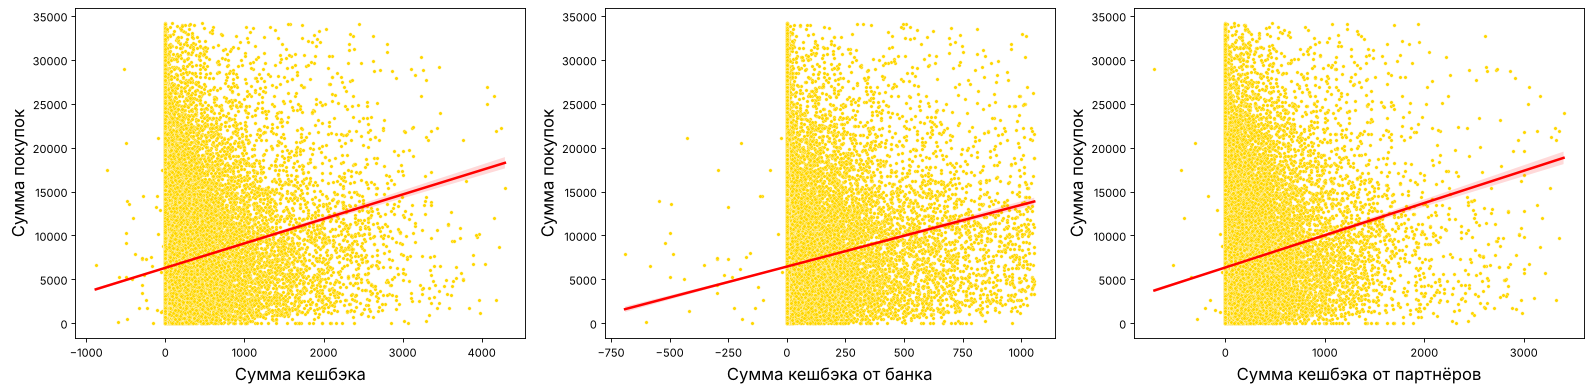

In [59]:
#cоздаем подграфики для каждого столбца в одну строку
fig, axes = plt.subplots(nrows=1, ncols=len(columns), figsize=(20, 5))
for ax, col, name in zip(axes, columns, names):
    sns.scatterplot(data = last_3_month, x=col, y='sum_after', ax=ax, s=10, color='#FFD700')  # Увеличиваем размер точек до 10
    sns.regplot(data=last_3_month, x=col, y='sum_after', ax=ax, scatter=False, color='red')
    ax.set_xlabel(name, fontsize=15)
    ax.set_ylabel('Сумма покупок', fontsize=15)
plt.tight_layout()
plt.show()

<Axes: >

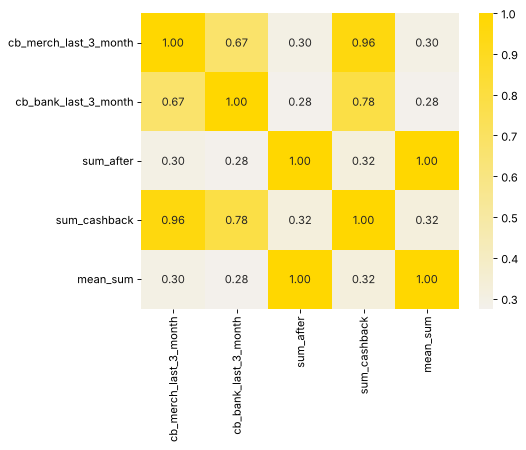

In [60]:
sns.heatmap(last_3_month.corr(method='spearman'), annot=True, cmap=sns.light_palette(color='#FFD700', as_cmap=True), fmt=".2f")

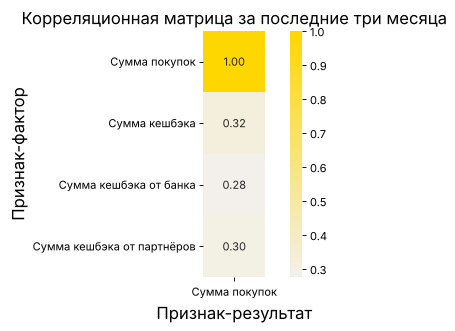

In [61]:
#корреляционная матрица
correlation_matrix = last_3_month[['sum_after', 'sum_cashback', 'cb_bank_last_3_month', 'cb_merch_last_3_month']].corr(method='spearman')
#названия переменных
custom_labels = {
    'sum_after': 'Сумма покупок',
    'sum_cashback': 'Сумма кешбэка',
    'cb_bank_last_3_month': 'Сумма кешбэка от банка',
    'cb_merch_last_3_month': 'Сумма кешбэка от партнёров',
}
#визуализация
plt.figure(figsize=(8, 4))
sns.heatmap(pd.DataFrame(correlation_matrix.loc['sum_after']), annot=True, fmt=".2f", cmap=sns.light_palette(color='#FFD700', as_cmap=True), square=True,
            xticklabels=[custom_labels['sum_after']], 
            yticklabels=[custom_labels[col] for col in correlation_matrix.columns])
plt.title('Корреляционная матрица за последние три месяца', fontsize=15)
plt.xlabel('Признак-результат', fontsize=15)
plt.ylabel('Признак-фактор', fontsize=15)
plt.show()

Сумма расходов за последние 3 месяца также имеет слабую связь с кэшбэком

In [62]:
spearman_corr, spearman_pval = spearmanr(last_3_month['sum_after'], last_3_month['sum_cashback'])
print(f"Коэффициент корреляции Спирмена: {spearman_corr}, p-значение: {spearman_pval}")

Коэффициент корреляции Спирмена: 0.32255827448944263, p-значение: 0.0


За последние 3 месяца связь между суммой покупок и суммой кешбэка также слабая положительная

 Коэффициент корреляции Спирмена равен 0.323, что указывает на умеренную положительную корреляцию между суммой покупок и суммой кешбэка после обновления. После обновления связь стала еще менее умеренной

#### Анализ категоризации пользователей по сумме покупок

In [63]:
#осуществляем категоризацию
last_3_month['sum_after_interval_cut'] = pd.cut(last_3_month['sum_after'], bins=4, labels=['малые траты', 'средние траты', 'траты выше среднего', 'высокие траты'])
last_3_month.head(1)

,cb_merch_last_3_month,cb_bank_last_3_month,sum_after,sum_cashback,mean_sum,sum_after_interval_cut
0,282.0,141.0,12832.0,423.0,802.0,средние траты


In [64]:
last_3_month['sum_after'].value_counts(bins=4)

(-34.198, 8549.25]     30702
(8549.25, 17098.5]      9946
(17098.5, 25647.75]     2827
(25647.75, 34197.0]      872
Name: count, dtype: int64

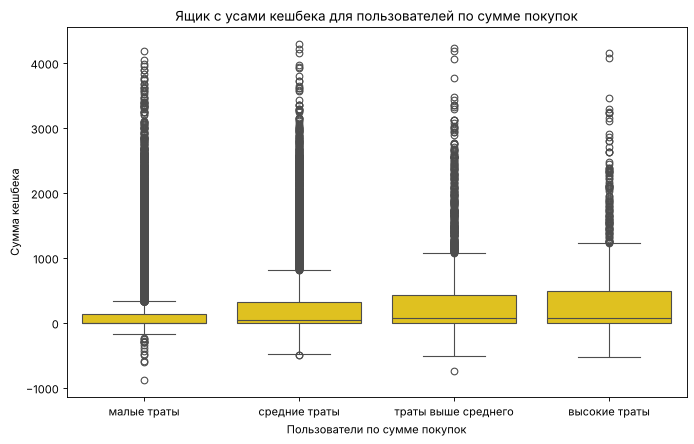

In [65]:
plt.figure(figsize=(10, 6))
sns.boxplot(y='sum_cashback', x='sum_after_interval_cut', data=last_3_month, color='#FFD700')
plt.xlabel('Пользователи по сумме покупок')
plt.ylabel('Сумма кешбека')
plt.title('Ящик с усами кешбека для пользователей по сумме покупок')
plt.show()

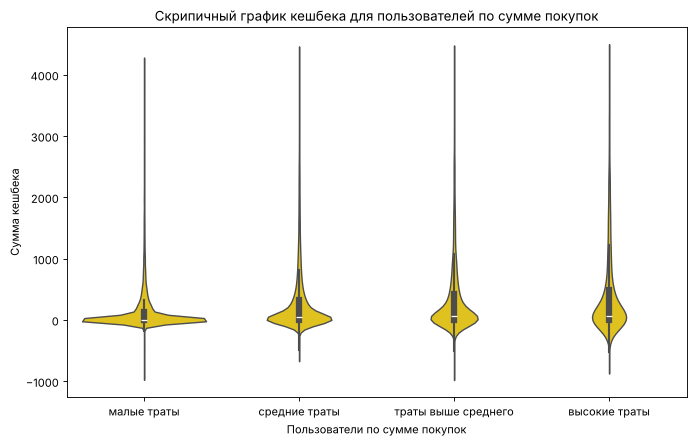

In [66]:
plt.figure(figsize=(10, 6))
sns.violinplot(y='sum_cashback', x='sum_after_interval_cut', data=last_3_month, color='#FFD700')
plt.xlabel('Пользователи по сумме покупок')
plt.ylabel('Сумма кешбека')
plt.title('Скрипичный график кешбека для пользователей по сумме покупок')
plt.show()

 Из анализа боксплотов и скрипичных графиков видно, что медиана суммы кешбека незначительно растет с объемом покупок. Также растет межквартильный размах, что говорит об увеличении устойчивости данных. По скрипкам видно, что с переходом в следующую группу данные распределяются равномернее. А количество  выбросов уменьшается, это объясняется, тем что количество наблюдений уменьшается с переходом в другую группы. Отрицательные выбросы не наблюдаются только у группы пользователей с высокими тратами. После обновления межквартильный размах существенно уменьшился, а количество выбросов для групп со средними, выше средними и высокими тратами увеличилось 

#### Анализ категоризации пользователей по сумме выплат

In [67]:
#осуществляем категоризацию
last_3_month['sum_cashback_interval_cut'] = pd.cut(last_3_month['sum_cashback'], bins=4, labels=['малые выплаты', 'средние выплаты', 'выплаты выше среднего', 'высокие выплаты'])
last_3_month.head(1)

,cb_merch_last_3_month,cb_bank_last_3_month,sum_after,sum_cashback,mean_sum,sum_after_interval_cut,sum_cashback_interval_cut
0,282.0,141.0,12832.0,423.0,802.0,средние траты,средние выплаты


In [68]:
last_3_month['sum_cashback'].value_counts(bins=4)

(-884.173, 414.0]    37833
(414.0, 1707.0]       5460
(1707.0, 3000.0]       942
(3000.0, 4293.0]       112
Name: count, dtype: int64

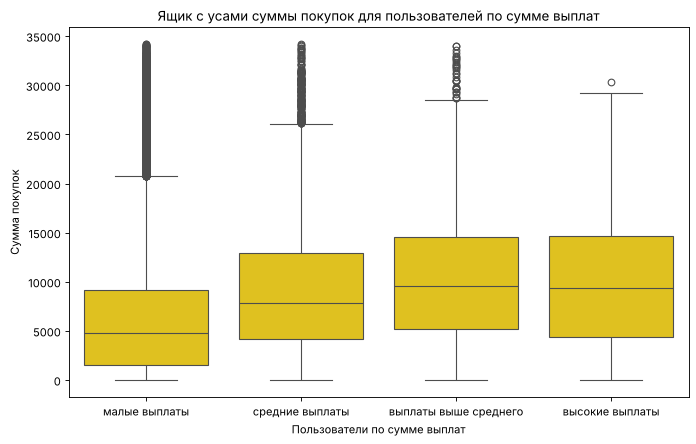

In [69]:
plt.figure(figsize=(10, 6))
sns.boxplot(y='sum_after', x='sum_cashback_interval_cut', data=last_3_month, color='#FFD700')
plt.xlabel('Пользователи по сумме выплат')
plt.ylabel('Сумма покупок')
plt.title('Ящик с усами суммы покупок для пользователей по сумме выплат')
plt.show()

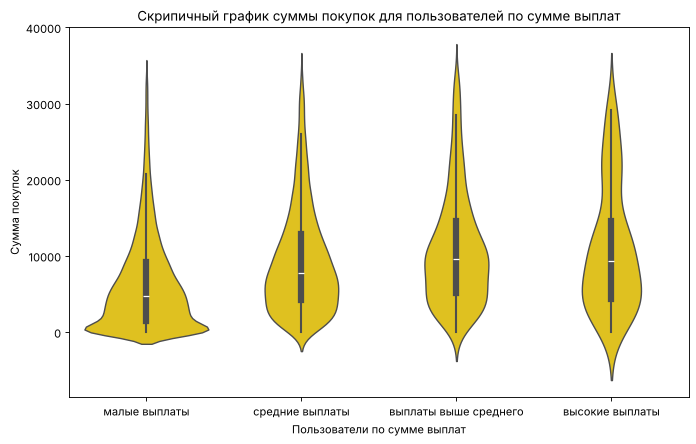

In [70]:
plt.figure(figsize=(10, 6))
sns.violinplot(y='sum_after', x='sum_cashback_interval_cut', data=last_3_month, color='#FFD700')
plt.xlabel('Пользователи по сумме выплат')
plt.ylabel('Сумма покупок')
plt.title('Скрипичный график суммы покупок для пользователей по сумме выплат')
plt.show()

 Из анализа боксплотов и скрипичных графиков видно, что медиана суммы покупок незначительно растет с объемом выплат. Также незначительно растет межквартильный размах, что говорит об увеличении устойчивости данных. По скрипкам видно, что с переходом в следующую группу данные распределяются равномернее. А количество  выбросов уменьшается, это объясняется, тем что количество наблюдений уменьшается с переходом в другую группы. Визуально после обновления графики не особо отличаются от графиков до внедрения обновления

# Исследование влияния обновления на сумму выплаченного кешбека

#### Создание датафрейма

In [71]:
#создаем словарь
dct = {'client_id': data['client_id'],
       'cb_before': data[['cb_merch_before', 'cb_bank_before']].sum(axis=1), #суммируем нужные столбцы
      'cb_after': data[['cb_merch_last_3_month', 'cb_bank_last_3_month']].sum(axis=1), #суммируем нужные столбцы
      }

In [72]:
#создаем датафрейм
df = pd.DataFrame(data=dct)
df.head(1)

,client_id,cb_before,cb_after
0,162353149,244.0,423.0


In [73]:
np.random.seed(123)

#### Расчет объема выборки для дальнейшего проведения А/В теста

In [74]:
alpha = 0.05 #ошибка первого рода           
beta = 0.2 #ошибка второго рода                            
mde = -110 #желаемый эффект                
var_control = np.var(df['cb_before']) #дисперсия контрольной группы
var_test = np.var(df['cb_after']) #дисперсия тестовой группы
t_alpha = st.norm.ppf(1 - alpha / 2) #значение квантиля уровня 1 - alpha / 2
t_beta = st.norm.ppf(1 - beta) #значение квантиля уровня 1 - beta
n = int((t_alpha + t_beta) ** 2 * (var_control + var_test) / (mde ** 2)) #расчет объема выборки
print(f'Необходимый объём выборки - {n}')

Необходимый объём выборки - 381


 Размер нашего датасета позволяет сформировать выборку из 381 наблюдение!

#### Проверка условий использования параметрических тестов

In [75]:
#случайно берем 1000 раз выборочное среднее из выборки размером n
sample_cb_before = [df['cb_before'].sample(n, replace=False).mean() for _ in range(1000)]

<Axes: ylabel='Density'>

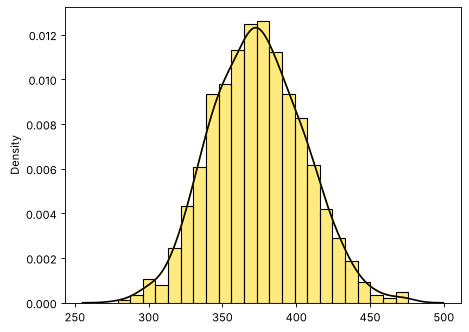

In [76]:
#визуализируем распределение
sns.histplot(sample_cb_before, color='#FFD700', kde=True, stat='density')
sns.kdeplot(sample_cb_before, color='black')

##### H0: Выборка выборочных средних имеет нормальное распределение<br><br>H1: Выборка выборочных средних НЕ имеет нормальное распределение

In [77]:
#проведим статистический тест Шапиро-Уилка на нормальность
stat, p = st.shapiro(sample_cb_before)
alpha = 0.05
if p < alpha:
    print(f'{p=:.3f} Отвергаем нулевую гипотезу. Выборка выборочных средних НЕ имеет нормального распределения')
else:
    print(f'{p=:.3f} Не получилось отвергнуть нулевую гипотезу. Выборка выборочных средних имеет нормальное распределение')

p=0.412 Не получилось отвергнуть нулевую гипотезу. Выборка выборочных средних имеет нормальное распределение


In [78]:
#случайно берем 1000 раз выборочное среднее из выборки размером n
sample_cb_after = [df['cb_after'].sample(n, replace=False).mean() for _ in range(1000)]

<Axes: ylabel='Density'>

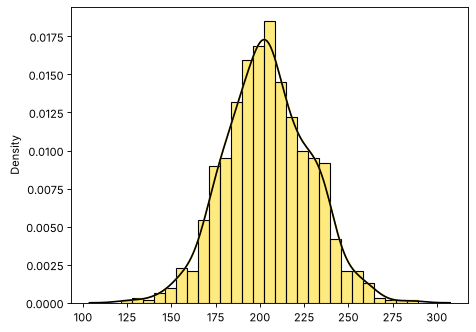

In [79]:
#визуализируем распределение
sns.histplot(sample_cb_after, color='#FFD700', kde=True, stat='density')
sns.kdeplot(sample_cb_after, color='black')

##### H0: Выборка выборочных средних имеет нормальное распределение<br><br>H1: Выборка выборочных средних НЕ имеет нормальное распределение

In [80]:
#проведем статистический тест Шапиро-Уилка
stat, p = st.shapiro(sample_cb_after)
alpha = 0.05
if p < alpha:
    print(f'{p=:.3f} Отвергаем нулевую гипотезу. Выборка выборочных средних НЕ имеет нормального распределения')
else:
    print(f'{p=:.3f} Не получилось отвергнуть нулевую гипотезу. Выборка выборочных средних имеет нормальное распределение')

p=0.488 Не получилось отвергнуть нулевую гипотезу. Выборка выборочных средних имеет нормальное распределение


 Выборки выборочных средних имеют нормальное распределение, а также наблюдения независимы, поэтому имеем полное право перейти к дальнейшему исследованию

#### Проведение А/А теста

In [81]:
p_values = [] #создаем пустой список
for i in range(1000): 
    sampled = np.random.choice(df['cb_before'], (n, 2)) #формируем массив nх2
    A = sampled[:, 0] #извлекаем массивы
    B = sampled[:, 1] #извлекаем массивы
    res = st.mannwhitneyu(A, B) #проводим непараметрический тест 
    p_values.append(res.pvalue) #закидываем получившийся результат в список               

<Axes: ylabel='Density'>

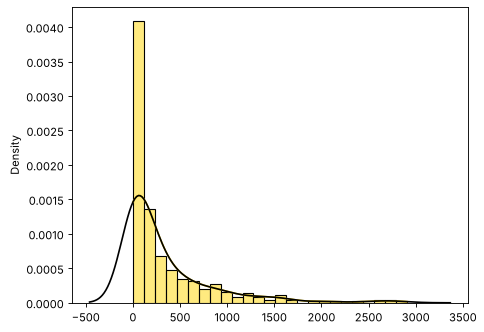

In [82]:
#визуализируем распределение
sns.histplot(A, color='#FFD700', kde=True, stat='density')
sns.kdeplot(A, color='black')

##### H0: Выборка имеет нормальное распределение<br><br>H1: Выборка НЕ имеет нормальное распределение

In [83]:
#проведем статистический тест Шапиро-Уилка на нормальность
stat, p = st.shapiro(A)
alpha = 0.05
if p < alpha:
    print(f'{p=:.3f} Отвергаем нулевую гипотезу. Выборка НЕ имеет нормального распределения')
else:
    print(f'{p=:.3f} Не получилось отвергнуть нулевую гипотезу. Выборка имеет нормальное распределение')

p=0.000 Отвергаем нулевую гипотезу. Выборка НЕ имеет нормального распределения


<Axes: ylabel='Density'>

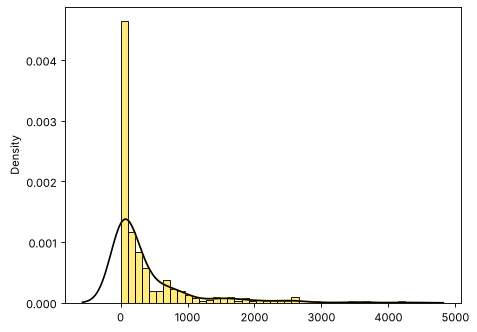

In [84]:
#визуализируем распределение
sns.histplot(B, color='#FFD700', kde=True, stat='density')
sns.kdeplot(B, color='black')

##### H0: Выборка имеет нормальное распределение<br><br>H1: Выборка НЕ имеет нормальное распределение

In [85]:
#проведем статистический тест Шапиро-Уилка на нормальность
stat, p = st.shapiro(B)
alpha = 0.05
if p < alpha:
    print(f'{p=:.3f} Отвергаем нулевую гипотезу. Выборка НЕ имеет нормального распределения')
else:
    print(f'{p=:.3f} Не получилось отвергнуть нулевую гипотезу. Выборка имеет нормальное распределение')

p=0.000 Отвергаем нулевую гипотезу. Выборка НЕ имеет нормального распределения


 Обе выборки не имеют нормального распределения, поэтому параметрические тесты к ним напрямую применять не рекомендуется. Используем бакетирование: средние по бакетам распределены приблизительно нормально (ЦПТ), и к ним можно применить t-тест.

In [86]:
#случайно разделяем так, чтобы в каждой группе было 30 наблюдений
bucket_A = np.array([np.mean(np.random.choice(A, size=30, replace=False)) for _ in range(int(n // 30))])

<Axes: ylabel='Density'>

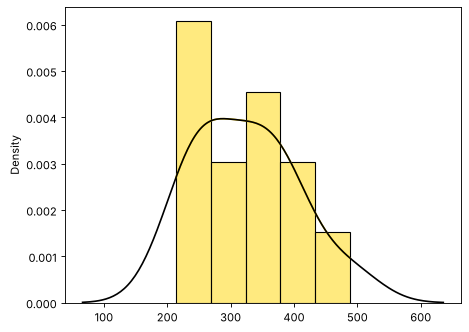

In [87]:
#визуализируем распределение
sns.histplot(bucket_A, color='#FFD700', kde=True, stat='density')
sns.kdeplot(bucket_A, color='black')

##### H0: Выборка имеет нормальное распределение<br><br>H1: Выборка НЕ имеет нормальное распределение

In [88]:
#проведем статистический тест Шапиро-Уилка на нормальность
stat, p = st.shapiro(bucket_A)
alpha = 0.05
if p < alpha:
    print(f'{p=:.3f} Отвергаем нулевую гипотезу. Выборка НЕ имеет нормального распределения')
else:
    print(f'{p=:.3f} Не получилось отвергнуть нулевую гипотезу. Выборка имеет нормальное распределение')

p=0.682 Не получилось отвергнуть нулевую гипотезу. Выборка имеет нормальное распределение


In [89]:
#случайно разделяем так, чтобы в каждой группе было 30 наблюдений
bucket_B = np.array([np.mean(np.random.choice(B, size=30, replace=False)) for _ in range(int(n // 30))])

<Axes: ylabel='Density'>

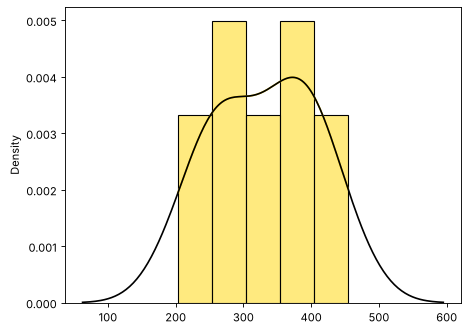

In [90]:
#визуализируем распределение
sns.histplot(bucket_B,color='#FFD700', kde=True, stat='density')
sns.kdeplot(bucket_B, color='black')

##### H0: Выборка имеет нормальное распределение<br><br>H1: Выборка НЕ имеет нормальное распределение

In [91]:
#проведем статистический тест Шапиро-Уилка на нормальность
stat, p = st.shapiro(bucket_B)
alpha = 0.05
if p < alpha:
    print(f'{p=:.3f} Отвергаем нулевую гипотезу. Выборка НЕ имеет нормального распределения')
else:
    print(f'{p=:.3f} Не получилось отвергнуть нулевую гипотезу. Выборка имеет нормальное распределение')

p=0.776 Не получилось отвергнуть нулевую гипотезу. Выборка имеет нормальное распределение


 Обе выборки имеют нормально распределение, поэтому можно применить параметрический тест!

##### H0: средние в группах не различаются<br><br>H1: средние в группах различаются

In [92]:
#проведем t-тест для независимых выборок (бакеты контроля и теста независимы)
alpha = 0.05
stat, p = st.ttest_ind(bucket_A, bucket_B)
if p < alpha:
    print(f'{p=:.3f} Отвергаем нулевую гипотезу. Выборки имеют статистически значимые отличия')
else:
    print(f'{p=:.3f} Не получилось отвергнуть нулевую гипотезу. Выборки НЕ имеют статистически значимых отличий')

p=0.821 Не получилось отвергнуть нулевую гипотезу. Выборки НЕ имеют статистически значимых отличий


<Axes: ylabel='Density'>

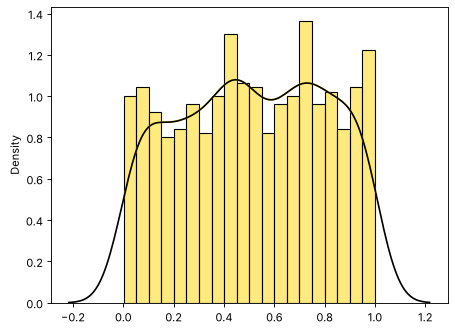

In [93]:
#визуализируем распределение
sns.histplot(p_values, color='#FFD700', bins=20, kde=True, stat='density')
sns.kdeplot(p_values, color='black')

##### H0: p-value A/A-тестов распределены равномерно на [0, 1]<br><br>H1: распределение p-value отличается от равномерного

In [94]:
#проверим равномерность распределения p-value A/A-тестов критерием Колмогорова–Смирнова
alpha = 0.05
ks_stat, p_value = st.kstest(p_values, 'uniform')
share_significant = np.mean(np.array(p_values) < alpha)
print(f'Доля ложноположительных A/A-тестов: {share_significant:.3f} (ожидается ≈ {alpha})')
if p_value < alpha:
    print(f'{p_value=:.3f} Отвергаем нулевую гипотезу. Распределение p-value НЕ равномерное')
else:
    print(f'{p_value=:.3f} Не получилось отвергнуть нулевую гипотезу. Распределение p-value равномерное')


Доля ложноположительных A/A-тестов: 0.046 (ожидается ≈ 0.05)
p_value=0.188 Не получилось отвергнуть нулевую гипотезу. Распределение p-value равномерное


 A/A-тест не выявил различий между одинаковыми группами, а распределение p-value близко к равномерному: система сплитования корректна, и A/B-тест имеет смысл.

#### Формирование тестовой и контрольной групп для А/В теста

In [95]:
#случайным образом формируем размером 2n, чтобы далее разделить пользователей по группам
groups = df.sample(n=2*n)
groups.head()

,client_id,cb_before,cb_after
41174,649164618,0.0,0.0
10258,209068503,0.0,0.0
31383,819280878,128.0,24.0
21378,393787623,0.0,0.0
31079,250125051,0.0,0.0


In [96]:
#случайным образом распределяем пользователей по группам
groups['group'] = np.random.choice(['control', 'test'], size=2*n)
groups.head()

,client_id,cb_before,cb_after,group
41174,649164618,0.0,0.0,test
10258,209068503,0.0,0.0,test
31383,819280878,128.0,24.0,test
21378,393787623,0.0,0.0,test
31079,250125051,0.0,0.0,control


In [97]:
#проверяем, что группы поделились примерно пополам
groups['group'].value_counts()

group
control    385
test       377
Name: count, dtype: int64

In [98]:
#исходя из распределения по группам присваиваем пользователю нужную метрику
groups['cb'] = groups.apply(lambda x: x['cb_before'] if x['group'] == 'control' else x['cb_after'], axis=1)
groups.head(1)

,client_id,cb_before,cb_after,group,cb
41174,649164618,0.0,0.0,test,0.0


In [99]:
#удаляем лишние столбцы
groups.drop(['cb_before', 'cb_after'], inplace=True, axis=1)
groups.head(1)

,client_id,group,cb
41174,649164618,test,0.0


In [100]:
#создаем датафрейм для конкретной группы
control = groups[groups['group'] == 'control']
control.head(1)

,client_id,group,cb
31079,250125051,control,0.0


<Axes: xlabel='cb', ylabel='Density'>

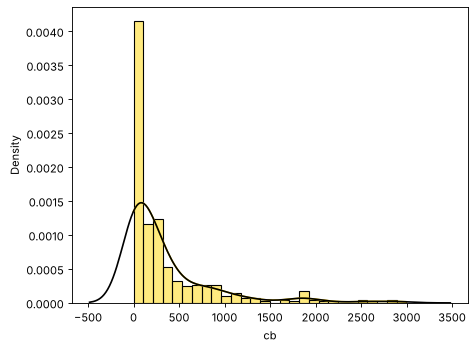

In [101]:
#визуализируем распределение
sns.histplot(control['cb'],color='#FFD700', kde=True, stat='density')
sns.kdeplot(control['cb'], color='black')

##### H0: Выборка имеет нормальное распределение<br><br>H1: Выборка НЕ имеет нормальное распределение

In [102]:
#проведем статистический тест Шапиро-Уилка на нормальность
stat, p = st.shapiro(control['cb'])
alpha = 0.05
if p < alpha:
    print(f'{p=:.3f} Отвергаем нулевую гипотезу. Выборка НЕ имеет нормального распределения')
else:
    print(f'{p=:.3f} Не получилось отвергнуть нулевую гипотезу. Выборка имеет нормальное распределение')

p=0.000 Отвергаем нулевую гипотезу. Выборка НЕ имеет нормального распределения


In [103]:
#создаем датафрейм для конкретной группы
test = groups[groups['group'] == 'test']
test.head(1)

,client_id,group,cb
41174,649164618,test,0.0


<Axes: xlabel='cb', ylabel='Density'>

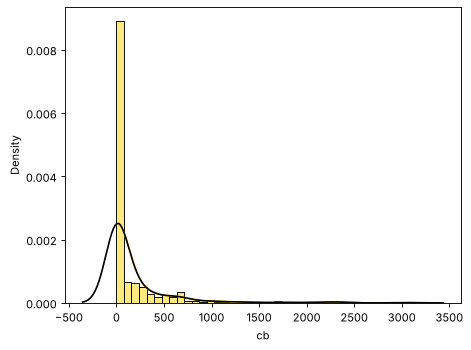

In [104]:
#визуализируем распределение
sns.histplot(test['cb'],color='#FFD700', kde=True, stat='density')
sns.kdeplot(test['cb'], color='black')

##### H0: Выборка имеет нормальное распределение<br><br>H1: Выборка НЕ имеет нормальное распределение

In [105]:
#проведем статистический тест Шапиро-Уилка на нормальность
stat, p = st.shapiro(test['cb'])
alpha = 0.05
if p < alpha:
    print(f'{p=:.3f} Отвергаем нулевую гипотезу. Выборка НЕ имеет нормального распределения')
else:
    print(f'{p=:.3f} Не получилось отвергнуть нулевую гипотезу. Выборка имеет нормальное распределение')

p=0.000 Отвергаем нулевую гипотезу. Выборка НЕ имеет нормального распределения


 Обе выборки не имеют нормального распределения, поэтому параметрические тесты к ним напрямую применять не рекомендуется. Используем бакетирование: средние по бакетам распределены приблизительно нормально (ЦПТ), и к ним можно применить t-тест.

In [106]:
#случайно разделяем так, чтобы в каждой группе было 30 наблюдений
bucket_control = np.array([control['cb'].sample(30, replace=False).mean() for _ in range(int(n // 30))])

<Axes: ylabel='Density'>

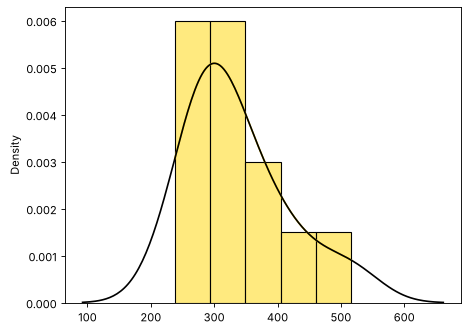

In [107]:
#визуализируем распределение
sns.histplot(bucket_control,color='#FFD700', kde=True, stat='density')
sns.kdeplot(bucket_control, color='black')

##### H0: Выборка имеет нормальное распределение<br><br>H1: Выборка НЕ имеет нормальное распределение

In [108]:
#проведем статистический тест Шапиро-Уилка на нормальность
stat, p = st.shapiro(bucket_control)
alpha = 0.05
if p < alpha:
    print(f'{p=:.3f} Отвергаем нулевую гипотезу. Выборка НЕ имеет нормального распределения')
else:
    print(f'{p=:.3f} Не получилось отвергнуть нулевую гипотезу. Выборка имеет нормальное распределение')

p=0.166 Не получилось отвергнуть нулевую гипотезу. Выборка имеет нормальное распределение


In [109]:
#случайно разделяем так, чтобы в каждой группе было 30 наблюдений
bucket_test = np.array([test['cb'].sample(30, replace=False).mean() for _ in range(int(n // 30))])

<Axes: ylabel='Density'>

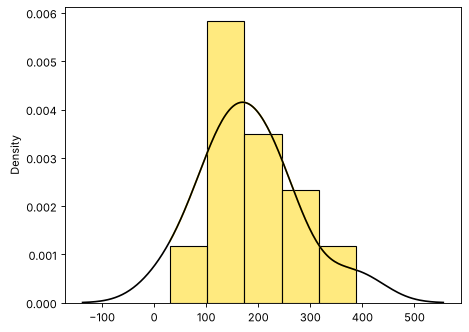

In [110]:
#визуализируем распределение
sns.histplot(bucket_test,color='#FFD700', kde=True, stat='density')
sns.kdeplot(bucket_test, color='black')

##### H0: Выборка имеет нормальное распределение<br><br>H1: Выборка НЕ имеет нормальное распределение

In [111]:
#проведем статистический тест Шапиро-Уилка на нормальность
stat, p = st.shapiro(bucket_test)
alpha = 0.05
if p < alpha:
    print(f'{p=:.3f} Отвергаем нулевую гипотезу. Выборка НЕ имеет нормального распределения')
else:
    print(f'{p=:.3f} Не получилось отвергнуть нулевую гипотезу. Выборка имеет нормальное распределение')

p=0.768 Не получилось отвергнуть нулевую гипотезу. Выборка имеет нормальное распределение


 Обе выборки имеют нормально распределение, поэтому можно применить параметрический тест!

##### H0: средние в группах не различаются<br><br>H1: средние в группах различаются

In [112]:
#проведем t-тест для независимых выборок (бакеты контроля и теста независимы)
alpha = 0.05
stat, p = st.ttest_ind(bucket_control, bucket_test)
if p < alpha:
    print(f'{p=:.5f}', 'Отвергаем нулевую гипотезу. Выборки имеют статистически значимые отличия')
else:
    print(f'{p=:.5f}', 'Не получилось отвергнуть нулевую гипотезу. Выборки НЕ имеют статистически значимых отличий')

p=0.00026 Отвергаем нулевую гипотезу. Выборки имеют статистически значимые отличия


 A/B-тест показал статистически значимое влияние обновления на метрику.

##### H0: Выборка разностей имеет статистически значимые отличаются от желаемого MDE — -110<br><br>H1: Выборка разностей НЕ имеет статистически значимых отличий от желаемого MDE — -110

In [113]:
#проверим, отличается ли разность средних от целевого MDE (z-тест)
alpha = 0.05
z = (np.mean(bucket_test) - np.mean(bucket_control) - mde) / np.sqrt((np.var(bucket_test) / int(n // 30)) + (np.var(bucket_control) / int(n // 30)))
p = 2 * (1 - st.norm.cdf(abs(z)))  # двусторонний p-value                                                                                                             
if p < alpha:
    print(f'{p=:.4f}', 'Отвергаем нулевую гипотезу. Разность средних отличается от целевого MDE')
else:
    print(f'{p=:.4f}', 'Не получилось отвергнуть нулевую гипотезу. Разность средних не отличается от целевого MDE')

p=0.2052 Не получилось отвергнуть нулевую гипотезу. Разность средних не отличается от целевого MDE


In [114]:
#рассчитаем доверительный интервал
alpha = 0.05
t_critical = st.norm.ppf(1 - alpha/2)
right = (np.mean(bucket_test) - np.mean(bucket_control)) + t_critical * np.sqrt((np.var(bucket_test) / int(n // 30)) + (np.var(bucket_control) / int(n // 30)))
left = (np.mean(bucket_test) - np.mean(bucket_control)) - t_critical * np.sqrt((np.var(bucket_test) / int(n // 30)) + (np.var(bucket_control) / int(n // 30)))
confidence_interval = (left, right)
print(f"95%-й доверительный интервал разности средних: ({left:.1f}; {right:.1f})")

95%-й доверительный интервал разности средних: (-218.5; -86.7)


 Разность средних статистически не отличается от целевого MDE: значение MDE попадает в 95%-й доверительный интервал разности.

# Исследование влияния обновления на сумму покупок

#### Создание датафрейма

In [115]:
#создаем словарь
dct = {'client_id': data['client_id'],
       'total_cost_before': data.loc[:, 'air_before':'transport_before'].sum(axis=1),
      'total_cost_after': data.loc[:, 'air':'transport'].sum(axis=1),
      }

In [116]:
#создаем датафрейм
df = pd.DataFrame(data=dct)
df.head(1)

,client_id,total_cost_before,total_cost_after
0,162353149,16800.0,12832.0


#### Расчет объема выборки для дальнейшего проведения А/В теста

In [117]:
alpha = 0.05 #ошибка первого рода           
beta = 0.2 #ошибка второго рода                            
mde = 550 #желаемый эффект                
var_control = np.var(df['total_cost_before']) #дисперсия контрольной группы
var_test = np.var(df['total_cost_after']) #дисперсия тестовой группы
t_alpha = st.norm.ppf(1 - alpha / 2) #значение квантиля уровня 1 - alpha / 2
t_beta = st.norm.ppf(1 - beta) #значение квантиля уровня 1 - beta
n = int((t_alpha + t_beta) ** 2 * (var_control + var_test) / (mde ** 2)) #расчет объема выборки
print(f'Необходимый объём выборки - {n}')

Необходимый объём выборки - 1942


 Размер нашего датасета позволяет сформировать выборку из 1942 наблюдения!

#### Проверка условий использования параметрических тестов

In [118]:
#случайно берем 1000 раз выборочное среднее из выборки размером n
sample_total_cost_before = [df['total_cost_before'].sample(n, replace=False).mean() for _ in range(1000)]

<Axes: ylabel='Density'>

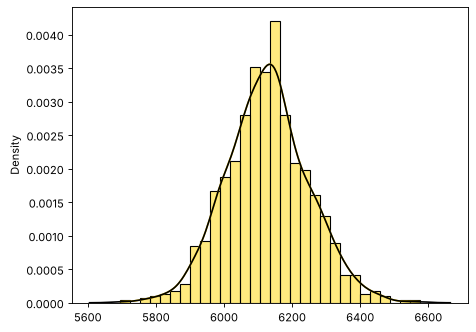

In [119]:
#визуализируем распределение
sns.histplot(sample_total_cost_before,color='#FFD700', kde=True, stat='density')
sns.kdeplot(sample_total_cost_before, color='black')

##### H0: Выборка имеет нормальное распределение<br><br>H1: Выборка НЕ имеет нормальное распределение

In [120]:
#проведем статистический тест Шапиро-Уилка на нормальность
stat, p = st.shapiro(sample_total_cost_before)
alpha = 0.05
if p < alpha:
    print(f'{p=:.3f}', 'Отвергаем нулевую гипотезу. Выборка выборочных средних НЕ имеет нормального распределения')
else:
    print(f'{p=:.3f}', 'Не получилось отвергнуть нулевую гипотезу. Выборка выборочных средних имеет нормальное распределение')

p=0.236 Не получилось отвергнуть нулевую гипотезу. Выборка выборочных средних имеет нормальное распределение


In [121]:
#случайно берем 1000 раз выборочное среднее из выборки размером n
sample_total_cost_after = [df['total_cost_after'].sample(n, replace=False).mean() for _ in range(1000)]

<Axes: ylabel='Density'>

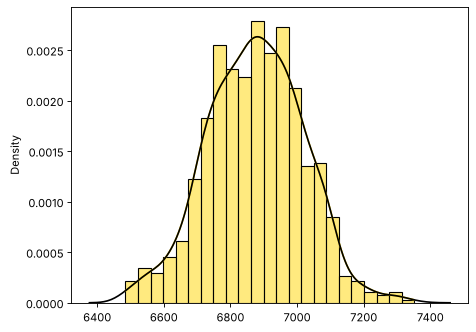

In [122]:
#визуализируем распределение
sns.histplot(sample_total_cost_after,color='#FFD700', kde=True, stat='density')
sns.kdeplot(sample_total_cost_after, color='black')

##### H0: Выборка имеет нормальное распределение<br><br>H1: Выборка НЕ имеет нормальное распределение

In [123]:
#проведем статистический тест Шапиро-Уилка на нормальность
stat, p = st.shapiro(sample_total_cost_after)
alpha = 0.05
if p < alpha:
    print(f'{p=:.3f}', 'Отвергаем нулевую гипотезу. Выборка выборочных средних НЕ имеет нормального распределения')
else:
    print(f'{p=:.3f}', 'Не получилось отвергнуть нулевую гипотезу. Выборка выборочных средних имеет нормальное распределение')

p=0.154 Не получилось отвергнуть нулевую гипотезу. Выборка выборочных средних имеет нормальное распределение


 Выборки выборочных средних имеют нормальное распределение, а также наблюдения независимы, поэтому имеем полное право перейти к дальнейшему исследованию

#### Проведение А/А теста

In [124]:
p_values = [] #создаем пустой список
for i in range(1000): 
    sampled = np.random.choice(df['total_cost_before'], (n, 2)) #формируем массив nх2
    A = sampled[:, 0] #извлекаем массивы
    B = sampled[:, 1] #извлекаем массивы
    res = st.mannwhitneyu(A, B) #проводим непараметрический тест 
    p_values.append(res.pvalue) #закидываем получившийся результат в список         

<Axes: ylabel='Density'>

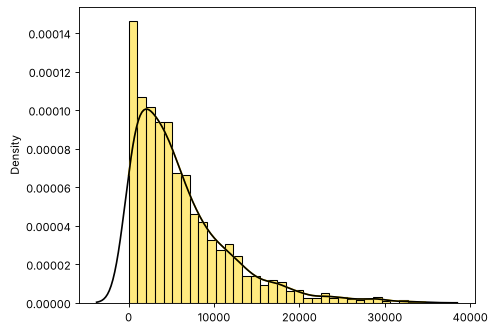

In [125]:
#визуализируем распределение
sns.histplot(A,color='#FFD700', kde=True, stat='density')
sns.kdeplot(A, color='black')

##### H0: Выборка имеет нормальное распределение<br><br>H1: Выборка НЕ имеет нормальное распределение

In [126]:
#проведем статистический тест Шапиро-Уилка на нормальность
stat, p = st.shapiro(A)
alpha = 0.05
if p < alpha:
    print(f'{p=:.3f}', 'Отвергаем нулевую гипотезу. Выборка НЕ имеет нормального распределения')
else:
    print(f'{p=:.3f}', 'Не получилось отвергнуть нулевую гипотезу. Выборка имеет нормальное распределение')

p=0.000 Отвергаем нулевую гипотезу. Выборка НЕ имеет нормального распределения


<Axes: ylabel='Density'>

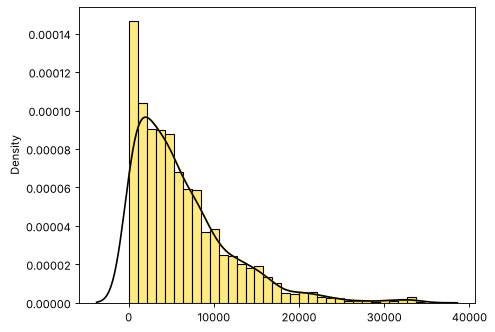

In [127]:
#визуализируем распределение
sns.histplot(B, color='#FFD700',kde=True, stat='density')
sns.kdeplot(B, color='black')

##### H0: Выборка имеет нормальное распределение<br><br>H1: Выборка НЕ имеет нормальное распределение

In [128]:
#проведем статистический тест Шапиро-Уилка на нормальность
stat, p = st.shapiro(B)
alpha = 0.05
if p < alpha:
    print(f'{p=:.3f}', 'Отвергаем нулевую гипотезу. Выборка НЕ имеет нормального распределения')
else:
    print(f'{p=:.3f}', 'Не получилось отвергнуть нулевую гипотезу. Выборка имеет нормальное распределение')

p=0.000 Отвергаем нулевую гипотезу. Выборка НЕ имеет нормального распределения


 Обе выборки не имеют нормального распределения, поэтому параметрические тесты к ним напрямую применять не рекомендуется. Используем бакетирование: средние по бакетам распределены приблизительно нормально (ЦПТ), и к ним можно применить t-тест.

In [129]:
#случайно разделяем так, чтобы в каждой группе было 30 наблюдений
bucket_A = np.array([np.mean(np.random.choice(A, size=30, replace=False)) for _ in range(int(n // 30))])

<Axes: ylabel='Density'>

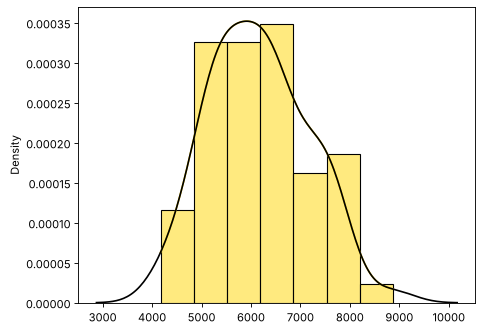

In [130]:
#визуализируем распределение
sns.histplot(bucket_A,color='#FFD700', kde=True, stat='density')
sns.kdeplot(bucket_A, color='black')

##### H0: Выборка имеет нормальное распределение<br><br>H1: Выборка НЕ имеет нормальное распределение

In [131]:
#проведем статистический тест Шапиро-Уилка на нормальность
stat, p = st.shapiro(bucket_A)
alpha = 0.05
if p < alpha:
    print(f'{p=:.3f} Отвергаем нулевую гипотезу. Выборка НЕ имеет нормального распределения')
else:
    print(f'{p=:.3f} Не получилось отвергнуть нулевую гипотезу. Выборка имеет нормальное распределение')

p=0.450 Не получилось отвергнуть нулевую гипотезу. Выборка имеет нормальное распределение


In [132]:
#случайно разделяем так, чтобы в каждой группе было 30 наблюдений
bucket_B = np.array([np.mean(np.random.choice(B, size=30, replace=False)) for _ in range(int(n // 30))])

<Axes: ylabel='Density'>

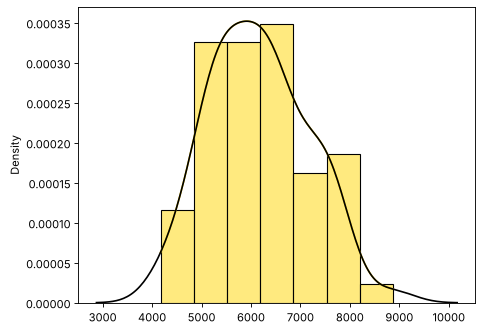

In [133]:
#визуализируем распределение
sns.histplot(bucket_A,color='#FFD700', kde=True, stat='density')
sns.kdeplot(bucket_A, color='black')

##### H0: Выборка имеет нормальное распределение<br><br>H1: Выборка НЕ имеет нормальное распределение

In [134]:
#проведем статистический тест Шапиро-Уилка на нормальность
stat, p = st.shapiro(bucket_B)
alpha = 0.05
if p < alpha:
    print(f'{p=:.3f} Отвергаем нулевую гипотезу. Выборка НЕ имеет нормального распределения')
else:
    print(f'{p=:.3f} Не получилось отвергнуть нулевую гипотезу. Выборка имеет нормальное распределение')

p=0.246 Не получилось отвергнуть нулевую гипотезу. Выборка имеет нормальное распределение


 Обе выборки имеют нормально распределение, поэтому можно применить параметрический тест!

##### H0: средние в группах не различаются<br><br>H1: средние в группах различаются

In [138]:
#проведем t-тест для независимых выборок (бакеты контроля и теста независимы)
alpha = 0.05
stat, p = st.ttest_ind(bucket_A, bucket_B)
if p < alpha:
    print(f'{p=:.3f} Отвергаем нулевую гипотезу. Выборки имеют статистически значимые отличия')
else:
    print(f'{p=:.3f} Не получилось отвергнуть нулевую гипотезу. Выборки НЕ имеют статистически значимых отличий')

p=0.894 Не получилось отвергнуть нулевую гипотезу. Выборки НЕ имеют статистически значимых отличий


<Axes: ylabel='Density'>

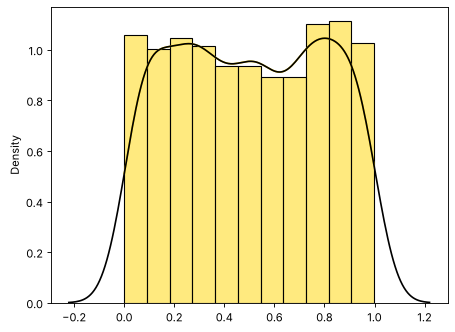

In [140]:
sns.histplot(p_values,color='#FFD700', kde=True,stat='density')
sns.kdeplot(p_values, color='black')

##### H0: p-value A/A-тестов распределены равномерно на [0, 1]<br><br>H1: распределение p-value отличается от равномерного

In [141]:
#проверим равномерность распределения p-value A/A-тестов критерием Колмогорова–Смирнова
alpha = 0.05
ks_stat, p_value = st.kstest(p_values, 'uniform')
share_significant = np.mean(np.array(p_values) < alpha)
print(f'Доля ложноположительных A/A-тестов: {share_significant:.3f} (ожидается ≈ {alpha})')
if p_value < alpha:
    print(f'{p_value=:.3f} Отвергаем нулевую гипотезу. Распределение p-value НЕ равномерное')
else:
    print(f'{p_value=:.3f} Не получилось отвергнуть нулевую гипотезу. Распределение p-value равномерное')


Доля ложноположительных A/A-тестов: 0.045 (ожидается ≈ 0.05)
p_value=0.635 Не получилось отвергнуть нулевую гипотезу. Распределение p-value равномерное


 A/A-тест не выявил различий между одинаковыми группами, а распределение p-value близко к равномерному: система сплитования корректна, и A/B-тест имеет смысл.

#### Формирование тестовой и контрольной групп для А/В теста

In [142]:
#случайным образом формируем размером 2n, чтобы далее разделить пользователей по группам
groups = df.sample(n=2*n)
groups.head(1)

,client_id,total_cost_before,total_cost_after
47004,694759312,1802.0,2396.0


In [143]:
#случайным образом распределяем пользователей по группам
groups['group'] = np.random.choice(['control', 'test'], size=2*n)
groups.head(1)

,client_id,total_cost_before,total_cost_after,group
47004,694759312,1802.0,2396.0,control


In [144]:
#проверяем, что группы поделились примерно пополам
groups['group'].value_counts()

group
control    1950
test       1934
Name: count, dtype: int64

In [145]:
#исходя из распределения по группам присваиваем пользователю нужную метрику
groups['total_cost'] = groups.apply(lambda x: x['total_cost_before'] if x['group'] == 'control' else x['total_cost_after'], axis=1)
groups.head(1)

,client_id,total_cost_before,total_cost_after,group,total_cost
47004,694759312,1802.0,2396.0,control,1802.0


In [146]:
#удаляем лишние столбцы
groups.drop(['total_cost_before', 'total_cost_after'], inplace=True, axis=1)
groups.head(1)

,client_id,group,total_cost
47004,694759312,control,1802.0


In [147]:
#создаем датафрейм для конкретной группы
control = groups[groups['group'] == 'control']
control.head(1)

,client_id,group,total_cost
47004,694759312,control,1802.0


<Axes: xlabel='total_cost', ylabel='Density'>

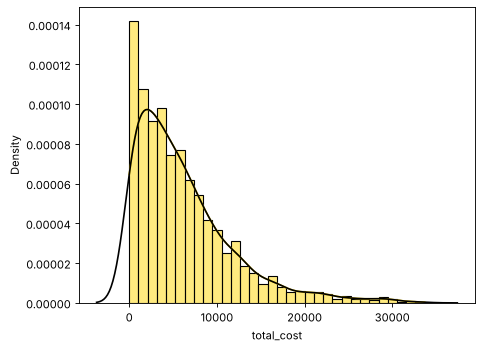

In [148]:
sns.histplot(control['total_cost'],color='#FFD700', kde=True, stat='density')
sns.kdeplot(control['total_cost'], color='black')

##### H0: Выборка имеет нормальное распределение<br><br>H1: Выборка НЕ имеет нормальное распределение

In [149]:
#проведем статистический тест Шапиро-Уилка
stat, p = st.shapiro(control['total_cost'])
alpha = 0.05
if p < alpha:
    print(f'{p=:.3f}', 'Отвергаем нулевую гипотезу. Выборка НЕ имеет нормального распределения')
else:
    print(f'{p=:.3f}', 'Не получилось отвергнуть нулевую гипотезу. Выборка имеет нормальное распределение')

p=0.000 Отвергаем нулевую гипотезу. Выборка НЕ имеет нормального распределения


In [150]:
#создаем датафрейм для конкретной группы
test = groups[groups['group'] == 'test']
test.head(1)

,client_id,group,total_cost
12635,619153175,test,7790.0


<Axes: xlabel='total_cost', ylabel='Density'>

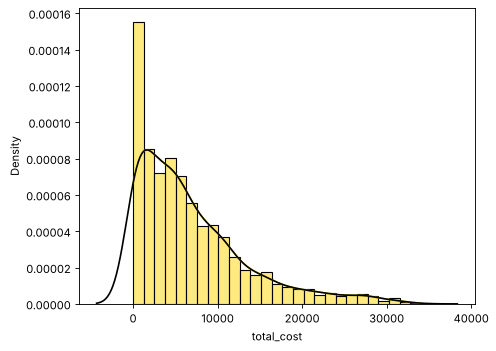

In [151]:
sns.histplot(test['total_cost'], color='#FFD700',kde=True, stat='density')
sns.kdeplot(test['total_cost'], color='black')

##### H0: Выборка имеет нормальное распределение<br><br>H1: Выборка НЕ имеет нормальное распределение

In [152]:
#проведем статистический тест Шапиро-Уилка
stat, p = st.shapiro(test['total_cost'])
alpha = 0.05
if p < alpha:
    print(f'{p=:.3f}', 'Отвергаем нулевую гипотезу. Выборка НЕ имеет нормального распределения')
else:
    print(f'{p=:.3f}', 'Не получилось отвергнуть нулевую гипотезу. Выборка имеет нормальное распределение')

p=0.000 Отвергаем нулевую гипотезу. Выборка НЕ имеет нормального распределения


 Обе выборки не имеют нормального распределения, поэтому параметрические тесты к ним напрямую применять не рекомендуется. Используем бакетирование: средние по бакетам распределены приблизительно нормально (ЦПТ), и к ним можно применить t-тест.

In [153]:
#случайно разделяем так, чтобы в каждой группе было 30 наблюдений
bucket_control = np.array([control['total_cost'].sample(30, replace=False).mean() for _ in range(int(n // 30))])

<Axes: ylabel='Density'>

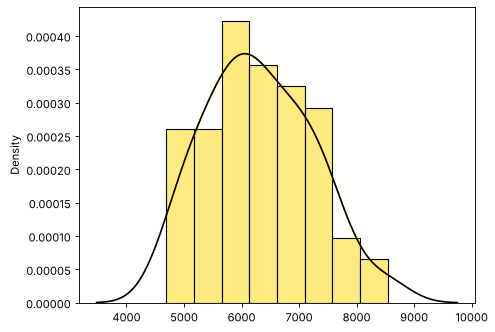

In [154]:
#визуализируем распределение
sns.histplot(bucket_control,color='#FFD700', kde=True, stat='density')
sns.kdeplot(bucket_control, color='black')

##### H0: Выборка имеет нормальное распределение<br><br>H1: Выборка НЕ имеет нормальное распределение

In [155]:
#проведем статистический тест Шапиро-Уилка на нормальность
stat, p = st.shapiro(bucket_control)
alpha = 0.05
if p < alpha:
    print(f'{p=:.3f} Отвергаем нулевую гипотезу. Выборка НЕ имеет нормального распределения')
else:
    print(f'{p=:.3f} Не получилось отвергнуть нулевую гипотезу. Выборка имеет нормальное распределение')

p=0.312 Не получилось отвергнуть нулевую гипотезу. Выборка имеет нормальное распределение


In [156]:
#случайно разделяем так, чтобы в каждой группе было 30 наблюдений
bucket_test = np.array([test['total_cost'].sample(30, replace=False).mean() for _ in range(int(n // 30))])

<Axes: ylabel='Density'>

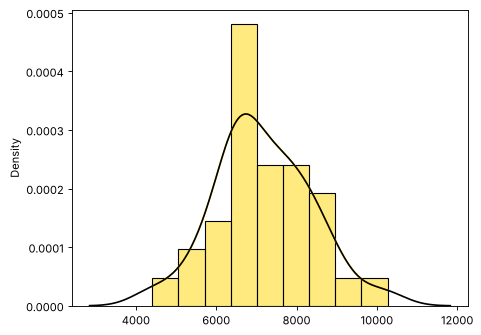

In [157]:
#визуализируем распределение
sns.histplot(bucket_test,color='#FFD700', kde=True, stat='density')
sns.kdeplot(bucket_test, color='black')

##### H0: Выборка имеет нормальное распределение<br><br>H1: Выборка НЕ имеет нормальное распределение

In [158]:
#проведем статистический тест Шапиро-Уилка на нормальность
stat, p = st.shapiro(bucket_test)
alpha = 0.05
if p < alpha:
    print(f'{p=:.3f} Отвергаем нулевую гипотезу. Выборка НЕ имеет нормального распределения')
else:
    print(f'{p=:.3f} Не получилось отвергнуть нулевую гипотезу. Выборка имеет нормальное распределение')

p=0.675 Не получилось отвергнуть нулевую гипотезу. Выборка имеет нормальное распределение


 Обе выборки имеют нормально распределение, поэтому можно применить параметрический тест!

##### H0: средние в группах не различаются<br><br>H1: средние в группах различаются

In [159]:
#проведем t-тест для независимых выборок (бакеты контроля и теста независимы)
alpha = 0.05
stat, p = st.ttest_ind(bucket_control, bucket_test)
if p < alpha:
    print(f'{p=:.3f}', 'Отвергаем нулевую гипотезу. Выборки имеют статистически значимые отличия')
else:
    print(f'{p=:.3f}', 'Не получилось отвергнуть нулевую гипотезу. Выборки НЕ имеют статистически значимых отличий')

p=0.000 Отвергаем нулевую гипотезу. Выборки имеют статистически значимые отличия


 A/B-тест показал статистически значимое влияние обновления на метрику.

##### H0: Выборка разностей имеет статистически значимые отличаются от желаемого MDE — 550<br><br>H1: Выборка разностей НЕ имеет статистически значимых отличий от желаемого MDE — 550

In [160]:
#проверим, отличается ли разность средних от целевого MDE (z-тест)
alpha = 0.05
z = (np.mean(bucket_test) - np.mean(bucket_control) - mde) / np.sqrt((np.var(bucket_test) / int(n // 30)) + (np.var(bucket_control) / int(n // 30)))
p = 2 * (1 - st.norm.cdf(abs(z)))  # двусторонний p-value                                                                                                             
if p < alpha:
    print(f'{p=:.4f}', 'Отвергаем нулевую гипотезу. Разность средних отличается от целевого MDE')
else:
    print(f'{p=:.4f}', 'Не получилось отвергнуть нулевую гипотезу. Разность средних не отличается от целевого MDE')

p=0.0975 Не получилось отвергнуть нулевую гипотезу. Разность средних не отличается от целевого MDE


In [161]:
#рассчитаем доверительный интервал
alpha = 0.05
t_critical = st.norm.ppf(1 - alpha/2)
right = (np.mean(bucket_test) - np.mean(bucket_control)) + t_critical * np.sqrt((np.var(bucket_test) / int(n // 30)) + (np.var(bucket_control) / int(n // 30)))
left = (np.mean(bucket_test) - np.mean(bucket_control)) - t_critical * np.sqrt((np.var(bucket_test) / int(n // 30)) + (np.var(bucket_control) / int(n // 30)))
confidence_interval = (left, right)
print(f"95%-й доверительный интервал разности средних: ({left:.1f}; {right:.1f})")

95%-й доверительный интервал разности средних: (493.1; 1229.4)


 Разность средних статистически не отличается от целевого MDE: значение MDE попадает в 95%-й доверительный интервал разности.

# Выдвижение собственной гипотезы

 Мы считаем, что для выдвижения собственной гипотезы недостаточно метрик. Основные количественные метрики - сумма покупок и сумма кешбека были проанализированы в 3 задании. Было выяснено, что обновление привело к росту покупок и снижению кешбека. Мы попытались составить метрики-отношения, например, сумма кешбека на единицу покупок, но изначально понятно, как эта метрика будет себя вести, так как сумма покупок и сумма кешбека имеет разное направление эффекта обновления. 